# Multimodal Graph Neural Networks for Movie Recommendation

### **Assignment Overview**
In this assignment, we will build a hybrid recommendation system using Computer Vision (CV), Natural Language Processing (NLP), and Graph Neural Networks (GNNs). You will complete three main tasks:

1. **Task 1: Computer Vision (CV)** - You will tackle multi-label movie genre classification using two approaches: training a custom CNN from scratch and fine-tuning a pre-trained model on movie posters. After comparing their performance, you will extract dense visual embeddings from the penultimate layer of your best-performing model to use in the final recommendation graph.
2. **Task 2: Natural Language Processing (NLP)** - Train an RNN or Transformer on movie plot summaries to predict genres, extracting semantic text embeddings.
3. **Task 3: Graph Neural Networks (GNN)** - Construct a bipartite user-item graph using the `ml-latest-small` MovieLens dataset. You will initialize the movie nodes using the embeddings extracted from Tasks 1 & 2, and train a GNN to perform link prediction (recommending movies to users).



## ⚠️ Important Instructions

Before you begin:

1. **Enable GPU**:
Deep learning models (especially CNNs and sequence models) take hours to train on a standard CPU. You **must** enable a GPU for this assignment (either in Google Colab or Kaggle.

2. **Training Time & Checkpointing**
The default epochs in the skeleton code are kept low just to ensure your code runs without crashing. **To get good performance, you might need to increase the number of epochs.** If you train for many epochs, your Colab or Kaggle session might disconnect and you will lose your progress. Be prepared to implement **model checkpointing** (`torch.save(model.state_dict(), 'checkpoint.pth')`) to save your weights during training.

3. **Adherence to Code Structure**:
The datasets and data-loading pipelines provided in this notebook are specifically engineered so that the outputs of Task 1 and Task 2 seamlessly plug into Task 3.
**Do not alter the predefined tensor shapes, variable names, or data splits.**

4. **Grading**
* **(Good):** Successfully completing the `TODO` sections, ensuring the code runs without errors, and writing a basic training loop will earn you a solid, passing grade.
* **Full Points (Excellent):** To achieve full marks, you are expected to go beyond the skeleton code. This means implementing relevant **optimizations** (as instructed) and achieving better than baseline F1-scores.

---

## Data Preparation
This section contains the **mandatory data preparation phase**. Read through the explanations to understand *why* we are formatting the data this way before you begin building your models.

You can use the provided curated dataset for consistency, or recreate it yourself by running the following cells. Note that recreating the data requires a [TMDB API](https://developer.themoviedb.org/docs/getting-started) key.



---
### **Download the Raw Data**
We need two datasets from GroupLens - [MovieLens](https://grouplens.org/datasets/movielens/):
* `ml-latest-small`: A small bipartite graph of 600 users and 9,000 movies. We will use this in **Task 3**.
* `ml-25m`: A massive dataset. We will extract a disjoint subset of movies from this to train our CV and NLP models in **Tasks 1 & 2**, ensuring our models learn on separate data before doing inference on the small graph.

In [15]:
import os

# Create a datasets directory
os.makedirs('datasets', exist_ok=True)

# Download and unzip the datasets
!wget -q https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
!wget -q https://files.grouplens.org/datasets/movielens/ml-25m.zip
!unzip -q -o ml-latest-small.zip -d datasets/
!unzip -q -o ml-25m.zip -d datasets/

---
### **Stratified Sampling**
To ensure our CV and NLP models generalize well to the final `ml-latest-small` graph, we perform **stratified sampling**. We calculate the distribution of "Decade + Primary Genre" in the small dataset, and force our training samples to match that exact distribution. If we train our CV and NLP models on a random subset of 15,000 movies from the massive 25M dataset, we might end up with a skewed distribution (e.g., too many 2010s Action movies and not enough 1950s Dramas) compared to our target ml-latest-small graph.

In [1]:
import pandas as pd
import numpy as np

def extract_metadata(df):
    """Extracts Decade and Primary Genre to create a sampling stratum."""
    df['year'] = df['title'].str.extract(r'\((\d{4})\)').astype(float)
    df['decade'] = (df['year'] // 10 * 10).fillna(0).astype(int)
    df['primary_genre'] = df['genres'].str.split('|').str[0]
    df['stratum'] = df['decade'].astype(str) + "_" + df['primary_genre']
    return df

In [2]:
print("Loading datasets...")
small_movies = pd.read_csv('datasets/ml-latest-small/movies.csv')
small_links = pd.read_csv('datasets/ml-latest-small/links.csv')

large_movies = pd.read_csv('datasets/ml-25m/movies.csv')
large_links = pd.read_csv('datasets/ml-25m/links.csv')

print("Processing metadata for stratified sampling...")
small_movies = extract_metadata(small_movies)
large_movies = extract_metadata(large_movies)

# Calculate target distribution from the small graph
target_distribution = small_movies['stratum'].value_counts(normalize=True)


Loading datasets...
Processing metadata for stratified sampling...


We prevent data leakage by creating a **disjoint** set of 15,000 movies to use for training on the image/text modalities.

In [3]:
# Find disjoint set (Movies in 25M that are NOT in latest-small)
small_ids = set(small_movies['movieId'])
disjoint_movies = large_movies[~large_movies['movieId'].isin(small_ids)].copy()

# Merge with TMDB links
# Discard movies with missing TMDB ids (database for plot summaries/posters)
disjoint_full = pd.merge(disjoint_movies, large_links, on='movieId')
disjoint_full = disjoint_full.dropna(subset=['tmdbId'])
disjoint_full['tmdbId'] = disjoint_full['tmdbId'].astype(int)

# Map weights and sample
disjoint_full['sample_weight'] = disjoint_full['stratum'].map(target_distribution).fillna(0)
train_subset = disjoint_full.sample(n=15000, weights='sample_weight', random_state=42)

# Merge small_movies with their TMDB links as well
small_full = pd.merge(small_movies, small_links, on='movieId')
small_full = small_full.dropna(subset=['tmdbId'])
small_full['tmdbId'] = small_full['tmdbId'].astype(int)

columns_to_keep = ['movieId', 'title', 'genres', 'tmdbId']
train_subset = train_subset[columns_to_keep]
small_full = small_full[columns_to_keep]

In [4]:
print(f"Stratified Training Subset: {len(train_subset)} movies.")
print(f"ML-Small Inference Target: {len(small_full)} movies.")

Stratified Training Subset: 15000 movies.
ML-Small Inference Target: 9734 movies.


---
### **Fetch Multimodal Data (Posters & Plots)**
We use the [TMDB API](https://developer.themoviedb.org/docs/getting-started) to asynchronously download posters and summaries. We fetch data for **both** the training set and the ML-Small set (needed for GNN embeddings later).

In order to access the API, you will need to sign up and generate an API key.

In [5]:
!pip install aiohttp

In [6]:
import asyncio
import aiohttp
from tqdm.asyncio import tqdm
from getpass import getpass

TMDB_API_KEY = getpass("Enter TMDB API Key: ")
IMAGE_DIR = "datasets/posters/"
os.makedirs(IMAGE_DIR, exist_ok=True)
IMAGE_BASE_URL = "https://image.tmdb.org/t/p/w185"

async def fetch_movie_data(session, tmdb_id, semaphore):
    url = f"https://api.themoviedb.org/3/movie/{tmdb_id}?api_key={TMDB_API_KEY}&language=en-US"
    async with semaphore:
        try:
            async with session.get(url) as response:
                if response.status != 200: return None
                data = await response.json()
                overview = data.get('overview', '')
                poster_path = data.get('poster_path', '')

                if not poster_path or not overview: return None

                img_url = f"{IMAGE_BASE_URL}{poster_path}"
                async with session.get(img_url) as img_response:
                    if img_response.status == 200:
                        img_filename = f"{tmdb_id}.jpg"
                        with open(os.path.join(IMAGE_DIR, img_filename), 'wb') as f:
                            f.write(await img_response.read())
                        return {"tmdbId": tmdb_id, "overview": overview, "poster_file": img_filename}
        except:
            return None

async def download_pipeline(df, output_csv_name):
    tmdb_ids = df['tmdbId'].unique()
    semaphore = asyncio.Semaphore(30)
    connector = aiohttp.TCPConnector(limit_per_host=30)

    async with aiohttp.ClientSession(connector=connector) as session:
        print(f"\nFetching data for {output_csv_name}...")
        tasks = [fetch_movie_data(session, tid, semaphore) for tid in tmdb_ids]
        results = await tqdm.gather(*tasks)

    valid_results = [res for res in results if res is not None]
    text_df = pd.DataFrame(valid_results)
    final_df = pd.merge(df, text_df, on='tmdbId')
    final_df.to_csv(f'datasets/{output_csv_name}', index=False)

KeyboardInterrupt: Interrupted by user

This takes about 10 minutes.

In [23]:
await download_pipeline(train_subset, "train_metadata_full.csv")
await download_pipeline(small_full, "ml_small_metadata_full.csv")
print("\nData preparation complete!")


Fetching data for train_metadata_full.csv...


100%|█████████████████████████████████████████████████████████████████████████████| 14997/14997 [06:13<00:00, 40.15it/s]



Fetching data for ml_small_metadata_full.csv...


100%|███████████████████████████████████████████████████████████████████████████████| 9733/9733 [04:04<00:00, 39.74it/s]


Data preparation complete!


In [24]:
!zip -r datasets.zip datasets/

  adding: datasets/ (stored 0%)
  adding: datasets/ml_small_metadata_full.csv (deflated 58%)
  adding: datasets/ml-latest-small/ (stored 0%)
  adding: datasets/ml-latest-small/ratings.csv (deflated 72%)
  adding: datasets/ml-latest-small/movies.csv (deflated 66%)
  adding: datasets/ml-latest-small/tags.csv (deflated 69%)
  adding: datasets/ml-latest-small/links.csv (deflated 56%)
  adding: datasets/ml-latest-small/README.txt (deflated 61%)
  adding: datasets/posters/ (stored 0%)
  adding: datasets/posters/470360.jpg (deflated 1%)
  adding: datasets/posters/39472.jpg (deflated 1%)
  adding: datasets/posters/29934.jpg (deflated 1%)
  adding: datasets/posters/14639.jpg (deflated 3%)
  adding: datasets/posters/284053.jpg (deflated 1%)
  adding: datasets/posters/422761.jpg (deflated 1%)
  adding: datasets/posters/47796.jpg (deflated 2%)
  adding: datasets/posters/40701.jpg (deflated 1%)
  adding: datasets/posters/8489.jpg (deflated 2%)
  adding: datasets/posters/57342.jpg (deflated 1%)
  ad

### **The PyTorch Dataset**
Let's create a PyTorch Custom Dataset for the CV portion.

## **Task 1:  Multi-Label Genre Classification of Movie Posters**

The first task of the assignment involves training a convolutional model to predict movie genres based on poster images and extracting the produced visual features.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!unzip -o /content/drive/MyDrive/datasets.zip -d datasets/

In [25]:
# Assuming datasets.zip is in the root of your Google Drive
#!unzip datasets.zip -d datasets/

Archive:  datasets.zip
   creating: datasets/datasets/
  inflating: datasets/datasets/ml_small_metadata_full.csv  
   creating: datasets/datasets/ml-latest-small/
  inflating: datasets/datasets/ml-latest-small/ratings.csv  
  inflating: datasets/datasets/ml-latest-small/movies.csv  
  inflating: datasets/datasets/ml-latest-small/tags.csv  
  inflating: datasets/datasets/ml-latest-small/links.csv  
  inflating: datasets/datasets/ml-latest-small/README.txt  
   creating: datasets/datasets/posters/
  inflating: datasets/datasets/posters/470360.jpg  
  inflating: datasets/datasets/posters/39472.jpg  
  inflating: datasets/datasets/posters/29934.jpg  
  inflating: datasets/datasets/posters/14639.jpg  
  inflating: datasets/datasets/posters/284053.jpg  
  inflating: datasets/datasets/posters/422761.jpg  
  inflating: datasets/datasets/posters/47796.jpg  
  inflating: datasets/datasets/posters/40701.jpg  
  inflating: datasets/datasets/posters/8489.jpg  
  inflating: datasets/datasets/posters

In [5]:
import pandas as pd

# Load train_metadata_full.csv into train_subset
train_subset = pd.read_csv('./datasets/train_metadata_full.csv')
small_full = pd.read_csv('./datasets/ml_small_metadata_full.csv')

print("train_metadata_full.csv loaded successfully into train_subset.")
print("ml_small_metadata_full.csv loaded successfully into small_full.")

train_metadata_full.csv loaded successfully into train_subset.
ml_small_metadata_full.csv loaded successfully into small_full.


**Multi-Hot Encoding the Target Variables**

You will frame genre prediction as a **Multi-Label Classification** problem. The required loss function expects the target to be a binary matrix (0s and 1s).

However, the genres look like this:

In [6]:
train_subset['genres'].head()

0             Drama
1             Drama
2            Comedy
3             Drama
4    Comedy|Musical
Name: genres, dtype: object

Use the correct binarizer from scikit-learn to transform the pipe-separated genres into the correct format.

In [7]:
import sklearn.preprocessing
from sklearn.preprocessing import MultiLabelBinarizer

# TODO: Instantiate the correct binarizer from sklearn for multi-label classification
mlb =MultiLabelBinarizer()

#TODO: complete encode_genres
def encode_genres(df):
    """
    Performs multi-hot encoding on pipe-delimited genre strings.

    Args:
        df (pd.DataFrame): Input data containing a 'genres' column.

    Returns:
        pd.DataFrame: The input DataFrame expanded with binary columns
                      for each unique genre identified by the binarizer.
    """

    # 1. Preprocess the 'genres' column so it is in the correct format for the binarizer.
    genres = df['genres'].str.split('|')
    # 2. Generate the multi-hot encoded matrix using your binarizer.
    encoded = mlb.fit_transform(genres)
    # 3. Return the new expanded dataframe.
    df_encoded = pd.DataFrame(encoded, columns=mlb.classes_)

    return pd.concat([df, df_encoded], axis=1)

train_subset = encode_genres(train_subset)
small_full = encode_genres(small_full)

print(f"Total unique genres: {len(mlb.classes_)}")
display(train_subset.head(3))

Total unique genres: 20


,movieId,title,genres,tmdbId,overview,poster_file,(no genres listed),Action,Adventure,Animation,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,126546,7 Days in Havana (2012),Drama,94904,"A lesbian, an aspiring actor, an aspiring sing...",94904.jpg,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,201432,Jacquot de Nantes (1991),Drama,41789,"Jacquot Demy, the son of a garage owner and a ...",41789.jpg,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,175827,Cedric the Entertainer: Taking You Higher (2006),Comedy,36256,Red-hot actor/comedian Cedric the Entertainer ...,36256.jpg,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Notice that TMDB posters are rectangular (~185x278).

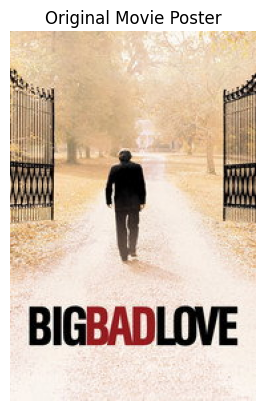

Image dimensions: 278x185 pixels (Height x Width)


In [8]:
import os
from PIL import Image
import matplotlib.pyplot as plt

id = train_subset.iloc[42]['tmdbId']

# Define the image directory
IMAGE_DIR = "./datasets/posters/"

# Construct the image path
image_filename = f"{id}.jpg"
image_path = os.path.join(IMAGE_DIR, image_filename)


image = Image.open(image_path)

# Display the image
plt.imshow(image)
plt.title(f"Original Movie Poster")
plt.axis('off')
plt.show()

# Print its dimensions
print(f"Image dimensions: {image.size[1]}x{image.size[0]} pixels (Height x Width)")

**Exploratory Data Analysis**

Before building any classification model, it is critical to understand the distribution of your target labels. If 80% of our movies are Dramas and only 2% are Westerns, the model might simply learn to predict "Drama" every time and ignore "Western" completely.

We will deal with this later.

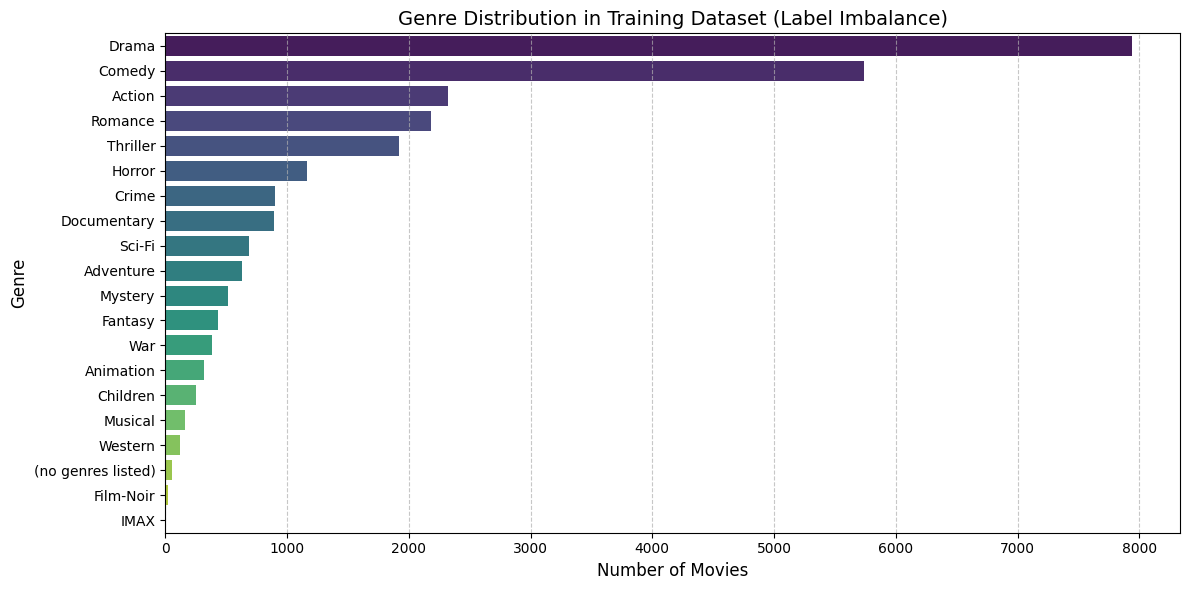

Top 3 Most Frequent Genres:
Drama     7936
Comedy    5742
Action    2325
dtype: int64

Bottom 3 Least Frequent Genres:
(no genres listed)    53
Film-Noir             22
IMAX                   8
dtype: int64


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

genre_columns = mlb.classes_

# Sum the occurrences of each genre
genre_counts = train_subset[genre_columns].sum().sort_values(ascending=False)

# Plotting the distribution
plt.figure(figsize=(12, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index, hue=genre_counts.index, palette="viridis", legend=False)
plt.title("Genre Distribution in Training Dataset (Label Imbalance)", fontsize=14)
plt.xlabel("Number of Movies", fontsize=12)
plt.ylabel("Genre", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Print the top 3 and bottom 3 genres
print("Top 3 Most Frequent Genres:")
print(genre_counts.head(3))
print("\nBottom 3 Least Frequent Genres:")
print(genre_counts.tail(3))

CNNs (like ResNet) expect square inputs, so you **must** apply a transform to resize/crop them.
Since we are training from scratch, we will use a resolution of **128x128 pixels** to ensure the model trains reasonably fast and fits within memory constraints.

Let's package the posters into a ``MoviePosterDataset`` class.

In [10]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class MoviePosterDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

        # Get the label columns directly from mlb.classes_
        # This ensures we always select only the genre columns by their names
        self_label_cols_ = list(mlb.classes_)
        self.label_cols = [col for col in self.dataframe.columns if col in self_label_cols_]

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        # TODO: Retrieve the image and its corresponding multi-hot labels for the given `idx`.

        # Make sure the image is opened as an RGB PIL image, processed through
        # `self.transform`, and that the labels are cast to a `torch.float32` tensor.
        # Return image, labels.
        row = self.dataframe.iloc[idx]

        # Build image path using tmdbId (matches how the download pipeline saved them)
        img_path = os.path.join(self.image_dir, f"{int(row['tmdbId'])}.jpg")

        # Convert to RGB — handles grayscale and RGBA posters gracefully
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        # Pull genre columns as float32 tensor for BCEWithLogitsLoss
        labels = torch.tensor(row[self.label_cols].values.astype(float), dtype=torch.float32)


        return image, labels


target_size = 128

# TODO: Define transforms (Resize, CenterCrop, ToTensor, Normalize)
poster_transform = transforms.Compose([
    transforms.Resize(target_size + 16),       # slight oversize before crop
    transforms.CenterCrop(target_size),        # crop to exact 128×128
    transforms.ToTensor(),                     # [0,255] PIL → [0.0,1.0] float tensor
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],            # ImageNet mean (R, G, B)
        std=[0.229, 0.224, 0.225]              # ImageNet std  (R, G, B)
    ),
])

In [11]:
from sklearn.model_selection import train_test_split

# Split the Training Data into Train and Validation (80/20)
train_df, val_df = train_test_split(train_subset, test_size=0.2, random_state=42)

# Instantiate the Datasets
print("Initializing Datasets...")
train_dataset = MoviePosterDataset(dataframe=train_df, image_dir=IMAGE_DIR, transform=poster_transform)
val_dataset = MoviePosterDataset(dataframe=val_df, image_dir=IMAGE_DIR, transform=poster_transform)

# Use the ML-Small dataset as our Test Set!
test_dataset = MoviePosterDataset(dataframe=small_full, image_dir=IMAGE_DIR, transform=poster_transform)


Initializing Datasets...


You can save `train_df, val_df` to use in following parts without having to regerate them, using the pickle format.




In [9]:
import pickle as pkl
pkl.dump(train_df, open("train_df.pkl", "wb"))
pkl.dump(val_df, open("val_df.pkl", "wb"))

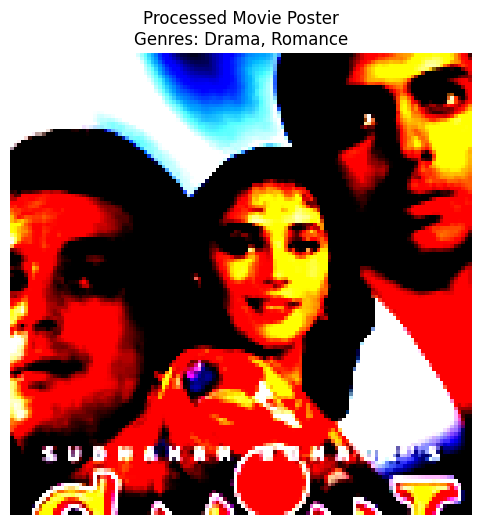

In [12]:
import numpy as np

image, labels = train_dataset[42]
# Convert tensor to numpy array and move channels to the last dimension (H, W, C)
image = image.numpy().transpose((1, 2, 0))
# # Clip values to [0, 1] as some values might be slightly outside due to floating point operations
image = np.clip(image, 0, 1)

# Get the genre names corresponding to the '1's in the labels
# The label_cols from MoviePosterDataset stores the order of genres
label_cols = train_dataset.label_cols
active_genres = [genre for i, genre in enumerate(label_cols) if labels[i] == 1]
genres_str = ', '.join(active_genres) if active_genres else 'No genres listed'

# Display the image
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title(f"Processed Movie Poster\nGenres: {genres_str}")
plt.axis('off')
plt.show()

In [13]:
batch_size = 64

# TODO: Create the train, validation and test loaders

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

print(f"Train Size: {len(train_dataset)} | Val Size: {len(val_dataset)} | Test (ML-Small) Size: {len(test_dataset)}")

print("For Training: ")
print(f"Number of Batches per Epoch: {len(train_loader)}")

sample_images, sample_labels = next(iter(train_loader))
print(f"Image Batch Shape: {sample_images.shape} -> [Batch, Channels, Height, Width]")
print(f"Label Batch Shape: {sample_labels.shape} -> [Batch, Num_Genres]")

Train Size: 11705 | Val Size: 2927 | Test (ML-Small) Size: 9617
For Training: 
Number of Batches per Epoch: 183
Image Batch Shape: torch.Size([64, 3, 128, 128]) -> [Batch, Channels, Height, Width]
Label Batch Shape: torch.Size([64, 20]) -> [Batch, Num_Genres]


---
### **Model Architecture (Multi-Label Classification)**
You will now build a Custom CNN from scratch.

Predicting genres is a **Multi-Label Classification** problem. A movie is rarely just one genre; it can be an *Action*, *Sci-Fi*, AND *Thriller* simultaneously.

**Your Task:**
1. Design a CNN feature extractor using `nn.Conv2d`, `nn.ReLU`, and `nn.MaxPool2d`. A typical architecture stacks 3 to 4 of these blocks.
2. Flatten the spatial dimensions and pass the features through a fully connected (`nn.Linear`) classification head.
3. The final output dimension must exactly match the number of unique genres in our dataset.
4. *Do not* apply a Softmax or Sigmoid layer at the very end of your `forward` pass. Why? Because PyTorch's recommended multi-label loss function expects raw, unnormalized logits.

In [14]:
import torch.nn as nn
import torch.nn.functional as F

class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super(CustomCNN, self).__init__()

        # TODO:
        # 1. Define your Convolutional feature extractor.
        #    Use a combination of nn.Conv2d, nn.ReLU, and nn.MaxPool2d.
        self.conv1 = nn.Conv2d(3, 32, kernel_size=4, padding=0)
        self.conv2 = nn.Conv2d(32,64,kernel_size=4, padding=0)
        self.pool = nn.MaxPool2d(2,2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=4, padding=0)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=4, padding=0)

        # 2. Calculate the size of the flattened tensor after the feature extractor.
        #    (Hint: Trace the spatial dimensions H x W and channels C of your input image
        #    through your conv and pool layers).
        self.flatten_dim = 6400

        # 3. Define your classification head. Use nn.Linear layers and add
        #    nn.Dropout to prevent overfitting. The first linear layer must accept
        #    your calculated flattened size.
     
        self.fc1 = nn.Linear(self.flatten_dim, num_classes)
        #self.dropout = nn.Dropout(0.5)
        #self.fc2 = nn.Linear(128, num_classes)
        


    def forward(self, x):
        # TODO: Implement the forward pass
        # 1. Pass the input `x` sequentially through your convolutional,
        #    activation (e.g., F.relu), and pooling layers.
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)
        x = self.conv3(x)
        x = F.relu(x)
        x = self.pool(x)
        x = self.conv4(x)
        x = F.relu(x)
        x = self.pool(x)
        # 2. Flatten the spatial dimensions of the feature maps so they can be
        #    passed into the classifier.
        x = x.view(x.size(0), -1)
        # 3. Pass the flattened tensor through the classification head to get the output logits.
        x = self.fc1(x)

        
        #x = F.relu(x)
        #x = self.dropout(x)
        #x = self.fc2(x)
        return x

    def extract_embeddings(self, x):
        """
        Helper function for Task 3:
        Runs the forward pass up to the penultimate layer and returns the dense feature vector.
        """
        # TODO: Implement feature extraction.
        # Implement the logic to return the output of your
        # final hidden layer BEFORE it hits the final classification layer.
        
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.pool(F.relu(self.conv4(x)))

        x = x.view(x.size(0), -1)
        #x = F.relu(self.fc1(x))
       
        

        return x

In [15]:
# Initialize the model
num_genres = len(mlb.classes_)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cv_model = CustomCNN(num_classes=num_genres).to(device)
print(f"Model initialized on: {device}")

Model initialized on: cuda


---
### **Training Loop & Loss Function**
To train this model, you need a loss function capable of handling multiple correct labels per image.
Standard `CrossEntropyLoss` (used for multi-class problems like identifying cats vs. dogs) will **not** work here, as it assumes only one class can be true.

**Your Task:**
1. Define the correct loss function.
2. Define an optimizer (e.g., `Adam` or `AdamW`) with a learning rate of your choice (e.g., `1e-3` or `1e-4`).
3. Complete the forward and backward pass inside the training loop.

Our dataset is heavily imbalanced. If we train normally, the model will just learn to predict "Drama" and "Comedy" for everything.

To fix this, we will calculate the **Positive Weight (`pos_weight`)** for each genre. This tells the loss function to assign a higher penalty when the model makes a mistake on a rare genre.
The formula is: `pos_weight = (Total Samples - Positive Samples) / Positive Samples`

In [16]:
# Get the number of positive occurrences for each genre in the training set
pos_counts = train_df[genre_columns].sum().values
total_samples = len(train_df)

# Calculate pos_weight: (negatives / positives)
pos_weights = (total_samples - pos_counts) / pos_counts
# Take the square root to dampen extreme values
smoothed_weights = np.sqrt(pos_weights)

# Convert to a PyTorch tensor and move to the device (GPU/CPU)
pos_weight_tensor = torch.tensor(smoothed_weights, dtype=torch.float32).to(device)

print("Calculated pos_weight for the first 5 genres:")
for i in range(20):
    print(f"{genre_columns[i]}: {pos_weight_tensor[i].item():.2f}")

Calculated pos_weight for the first 5 genres:
(no genres listed): 16.87
Action: 2.27
Adventure: 4.65
Animation: 6.71
Children: 7.72
Comedy: 1.25
Crime: 3.87
Documentary: 3.92
Drama: 0.92
Fantasy: 5.65
Film-Noir: 26.22
Horror: 3.40
IMAX: 40.88
Musical: 9.47
Mystery: 5.24
Romance: 2.38
Sci-Fi: 4.47
Thriller: 2.57
War: 6.00
Western: 10.94


In [ ]:
import torch.optim as optim
from tqdm import tqdm

# TODO: Define Loss Function and Optimizer
# Hint: use pos_weight
# criterion = ...
# optimizer = ...
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = optim.Adam(cv_model.parameters(), lr=0.001)


epochs = 15 # You may need more epochs when training from scratch

train_losses = []
val_losses = []

for epoch in range(epochs):
    # --- TRAINING PHASE ---
    cv_model.train()
    running_loss = 0.0
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")

    for images, labels in progress_bar:
        images, labels = images.to(device), labels.to(device)

        # TODO: Perform the standard PyTorch training step:
        # Compute the forward pass, calculate the loss, backpropagate the error,
        # and update the model weights.
        optimizer.zero_grad()
        outputs = cv_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Loss update
        running_loss += loss.item() * images.size(0)
        #progress_bar.set_postfix({'batch_loss': loss.item()})


    train_loss = running_loss / len(train_dataset)
    train_losses.append(train_loss) # Store for plotting

    # --- VALIDATION PHASE ---
    cv_model.eval()
    val_loss = 0.0

    # torch.no_grad() prevents PyTorch from storing gradients, saving memory during eval
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            # TODO: Compute the model's predictions,
            # and calculate the batch loss.
            outputs = cv_model(images)
            loss = criterion(outputs, labels)
            # Loss update
            val_loss += loss.item() * images.size(0)

    val_loss = val_loss / len(val_dataset)
    val_losses.append(val_loss) # Store for plotting

    print(f"End of Epoch {epoch+1} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

print("Training complete!")

Epoch 1/15 [Train]: 100%|█████████████████████████████████████████████████████████████| 183/183 [00:20<00:00,  8.90it/s]


End of Epoch 1 | Train Loss: 0.5171 | Val Loss: 0.4991


Epoch 2/15 [Train]: 100%|█████████████████████████████████████████████████████████████| 183/183 [00:15<00:00, 11.62it/s]


End of Epoch 2 | Train Loss: 0.4932 | Val Loss: 0.4858


Epoch 3/15 [Train]: 100%|█████████████████████████████████████████████████████████████| 183/183 [00:15<00:00, 11.75it/s]


...

Epoch 10/15 [Train]: 100%|████████████████████████████████████████████████████████████| 183/183 [00:16<00:00, 10.87it/s]


End of Epoch 10 | Train Loss: 0.4518 | Val Loss: 0.4958


Epoch 11/15 [Train]: 100%|████████████████████████████████████████████████████████████| 183/183 [00:16<00:00, 10.79it/s]


End of Epoch 11 | Train Loss: 0.4387 | Val Loss: 0.5037


Epoch 12/15 [Train]:  56%|█████████████████████████████████▍                          | 102/183 [00:09<00:07, 10.56it/s]

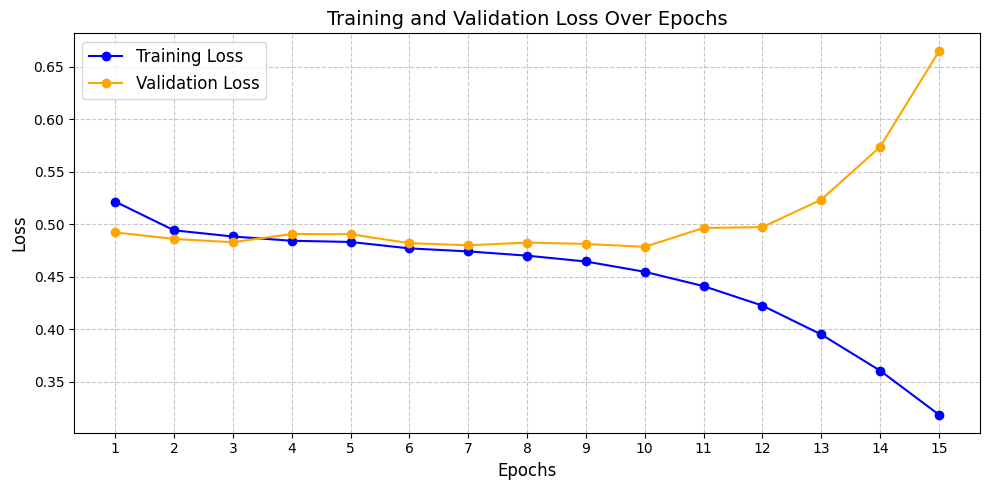

In [20]:
# --- VISUALIZE LOSS CURVES ---
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs+1), train_losses, label='Training Loss', marker='o', color='blue')
plt.plot(range(1, epochs+1), val_losses, label='Validation Loss', marker='o', color='orange')
plt.title('Training and Validation Loss Over Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.xticks(range(1, epochs+1))
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

---
### **Model Evaluation & Qualitative Analysis**

Now that your Custom CNN is trained, we need to evaluate how well it actually learned to identify genres.

In standard multi-class classification (e.g., identifying a dog vs. a cat), we usually just look at "Accuracy." However, in **multi-label classification**, exact-match accuracy is often overly strict and misleading. For example, if a movie is truly "Action|Sci-Fi|Thriller" and your model predicts "Action|Sci-Fi", it is partially correct, but exact accuracy would score it as a 0.

To properly evaluate your model, you will need to calculate metrics like **F1-Score** and **ROC-AUC**, and perform some qualitative "eye tests."




**1. Quantitative Metrics**
Write an evaluation loop (using a separate validation/test set) to calculate the following:
* **Sigmoid Activation:** Pass your model's raw output logits through a `torch.sigmoid()` function to convert them into probabilities (0.0 to 1.0).
* **Thresholding:** Convert those probabilities into binary predictions (0 or 1) using a threshold (e.g., `0.5`).
* **Macro F1-Score:** Calculate the F1-score for each genre independently, then take the unweighted average.
* **Micro F1-Score:** Calculate the F1-score globally by counting the total true positives, false negatives, and false positives across all classes.

Evaluating model on the Test Set (ML-Small)...


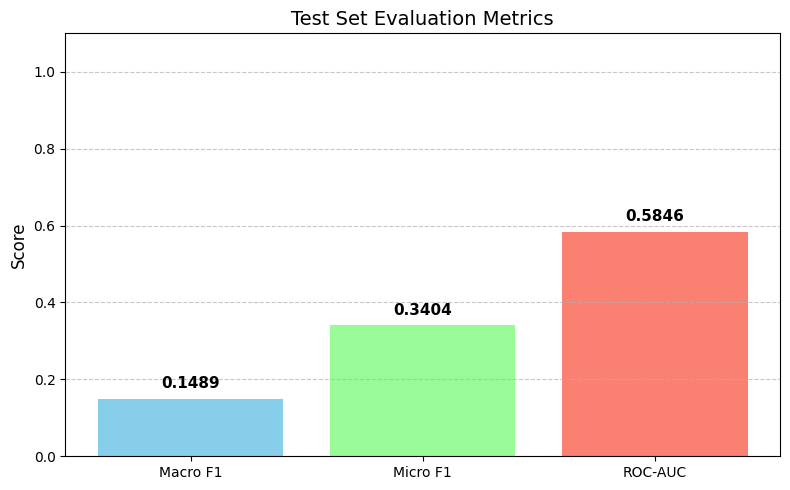

In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, roc_auc_score

# ==========================================
# 1. Quantitative Evaluation
# ==========================================
cv_model.eval()

# TODO: Populate these lists with numpy arrays during your evaluation loop
all_targets = []
all_predictions = []
binary_predictions = []
thresholds = []

print("Evaluating model on the Test Set (ML-Small)...")

# TODO:
# 1. Write the evaluation loop over `test_loader` (remember to disable gradients)
with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
# 2. Apply the correct activation function to get probabilities.
            outputs = cv_model(images)
            probabilities = torch.sigmoid(outputs)
            predictions = (probabilities > 0.5)
# 3. Append the true labels to `all_targets` and probabilities to `all_predictions`.
            all_targets.append(labels.cpu().numpy())
            all_predictions.append(probabilities.cpu().numpy())
            binary_predictions.append(predictions.cpu().numpy())


# 4. Stack them into continuous 2D numpy arrays.
all_targets = np.vstack(all_targets)
all_predictions = np.vstack(all_predictions)
binary_predictions = np.vstack(binary_predictions)
# 5. Create a `binary_predictions` array by thresholding probabilities at 0.5.

# TODO: Calculate the metrics.
# Hint: Pay attention to which metric needs binary predictions vs. continuous probabilities.
macro_f1 = f1_score(all_targets, binary_predictions, average='macro')
micro_f1 = f1_score(all_targets, binary_predictions, average='micro')
roc_auc = roc_auc_score(all_targets, all_predictions, average = 'macro')

# ==========================================
# --- VISUALIZE QUANTITATIVE METRICS ---
# ==========================================
metrics_dict = {'Macro F1': macro_f1, 'Micro F1': micro_f1, 'ROC-AUC': roc_auc}

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics_dict.keys(), metrics_dict.values(), color=['#87CEEB', '#98FB98', '#FA8072'])
plt.ylim(0, 1.1)
plt.title('Test Set Evaluation Metrics', fontsize=14)
plt.ylabel('Score', fontsize=12)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}',
             ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


**2. Qualitative Analysis**
Visualize your model's predictions to see if they make logical sense.
* Write a function to display a grid of 5 random movie posters from your dataset.
* Above each poster, print the **True Genres** and the **Predicted Genres** (any genre where the predicted probability was > 0.5).

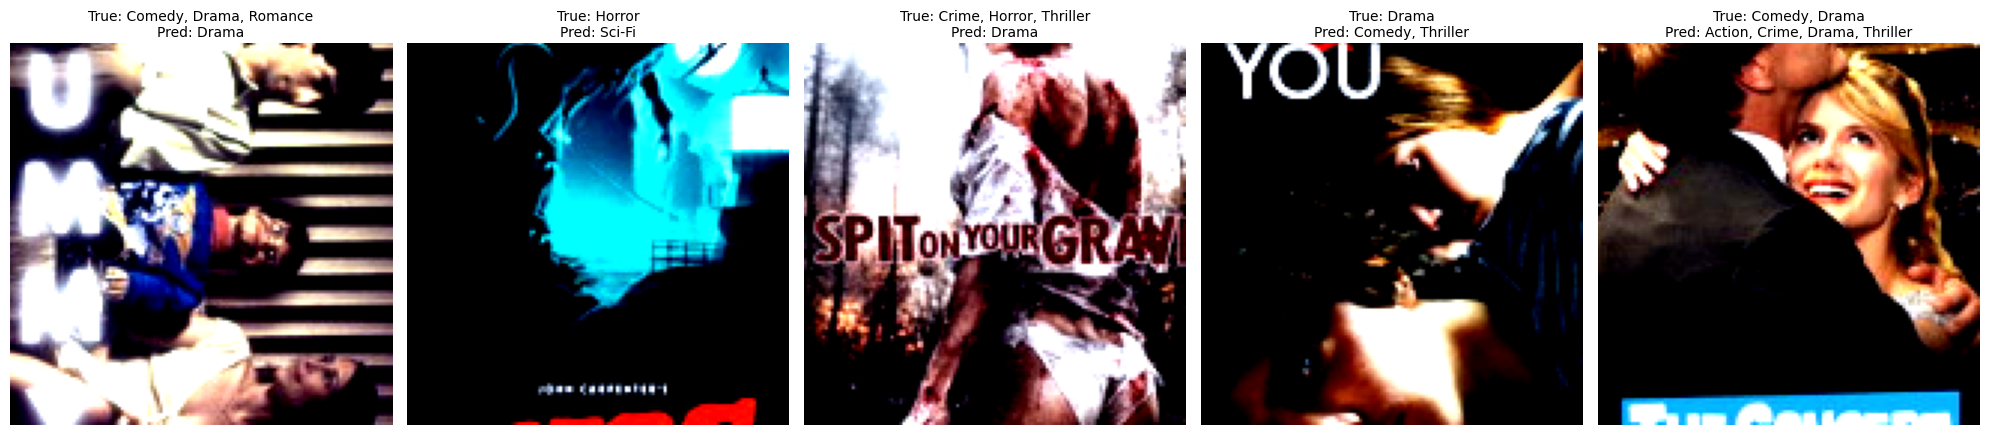

In [63]:
# ==========================================
# 2. Qualitative  (Visual Grid)
# ==========================================
from sklearn.metrics import classification_report
def imshow_denormalized(img):
    img = img / 2 + 0.5
    img = np.clip(img, 0, 1)
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))

# TODO: Extract exactly ONE batch of images and labels from the test_loader
# Get ONE batch
images, labels = next(iter(test_loader))

images, labels = images.to(device), labels.to(device)

# Get predictions
cv_model.eval()
with torch.no_grad():
    outputs = cv_model(images)
    probs = torch.sigmoid(outputs)
    preds = (probs >= 0.5).int()

# Move to CPU for numpy use
images = images.cpu()
labels = labels.cpu().numpy()
preds = preds.cpu().numpy()

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
genre_names = mlb.classes_

for i in range(5):
    ax = axes[i]

    # Get indices where value = 1
    true_indices = np.where(labels[i] == 1)[0]
    pred_indices = np.where(preds[i] == 1)[0]

    # Convert indices → genre names
    true_genres = [genre_names[j] for j in true_indices]
    pred_genres = [genre_names[j] for j in pred_indices]

    # ==========================================
    # Visualization
    # ==========================================
    plt.sca(ax)
    imshow_denormalized(images[i])
    ax.axis('off')

    title_text = f"True: {', '.join(true_genres)}\nPred: {', '.join(pred_genres) if pred_genres else 'None'}"
    color = 'green' if set(true_genres) == set(pred_genres) else 'black'
    ax.set_title(title_text, fontsize=10, wrap=True, color=color)

plt.tight_layout()
plt.show()


In [22]:
# Generatate per-class F1 scores
from sklearn.metrics import classification_report
import numpy as np
import torch

all_preds = []
all_labels = []

cv_model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        
        outputs = cv_model(images)
        probs = torch.sigmoid(outputs)
        preds = (probs >= 0.5).int()
        
        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels.numpy())

all_preds = np.concatenate(all_preds, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

report = classification_report(
    all_labels, 
    all_preds, 
    target_names=mlb.classes_, 
    zero_division=0
)

print(report)

                    precision    recall  f1-score   support

(no genres listed)       0.00      0.00      0.00        27
            Action       0.31      0.21      0.25      1806
         Adventure       0.22      0.09      0.13      1233
         Animation       0.24      0.13      0.17       599
          Children       0.27      0.07      0.12       660
            Comedy       0.56      0.53      0.55      3738
             Crime       0.18      0.04      0.07      1185
       Documentary       0.06      0.09      0.07       416
             Drama       0.51      0.68      0.58      4311
           Fantasy       0.12      0.05      0.07       756
         Film-Noir       0.00      0.00      0.00        87
            Horror       0.20      0.14      0.16       969
              IMAX       0.00      0.00      0.00       157
           Musical       0.08      0.02      0.04       328
           Mystery       0.08      0.04      0.05       557
           Romance       0.22      0.44

Answer below:

1. Why is standard "exact-match accuracy" a poor metric for this specific task? What happens to your F1-Score if you predict *every* movie is a "Drama" and "Comedy"?
2. **Threshold Tuning:** In your evaluation, you likely used a probability threshold of 0.5 to decide if a genre was present. If you lower this threshold to 0.3, how would you expect your Precision and Recall to change? Explain why.
3. **Class Imbalance:** Look at your per-class F1-scores. Which genres did your model perform best on, and which did it struggle with? Does this correlate with the frequency of those genres in the training data?
4. **Visual Ambiguity:** Based on your visual "eye test" of the posters, name one genre that you think is visually easy for a CNN to learn, and one genre that is visually ambiguous. Provide a brief justification based on how movie posters are designed.

Your answers:

1. "Exact-match" accuracy is a poor metric for this problem because it is a multilabel classification problem. This means that if the model doesn't predict all the correct labels, even though it predicts some of them, it will still get zero score.

2. By lowering the threshold the model will predict more correct genres but it will also include more wrong ones. The precision will decrease and the recall will increase.

3. Comedy and Drama are the genres with the highest F1-score (0.53 and 0.51 respectively). From the support values (4311 and 3738) we see that they are the most frequent genres in the dataset so the model was trained with more examples from these categories and learned their features better. On the other side, Film-Noir and IMAX that are very rare in the dataset have zero F1-scores.

4. A visually "easy" genre is Action. The posters often depict weapons, explosions, fighting poses, cars and have strong colors. These features appear frequently and the CNN can learn them easily.

A more ambiguous genre is Drama. Posters don't usually have a unique feature that distincts them. They can sometimes depict faces with intense emotions or have more natural colors but these features are abstract and can also appear in other genres.  


### **Optimization: Transfer Learning with Pre-trained ResNet**
Instead of training a CNN from scratch, you will now leverage Transfer Learning. Load a pre-trained ResNet18 or ResNet50 model from torchvision.models. Modify its final classification layer to output the correct number of genres, fine-tune it on the training set, and perform the same quantitative evaluation (Macro F1, Micro F1, ROC-AUC) on the ML-Small test set.

Python

Fine-tuning Pretrained ResNet...


Epoch 1/10 [Train]: 100%|███████████████████████████████████████████| 183/183 [00:14<00:00, 12.41it/s, batch_loss=0.513]


End of Epoch 1 | Val Loss: 0.4621


Epoch 2/10 [Train]: 100%|███████████████████████████████████████████| 183/183 [00:15<00:00, 12.03it/s, batch_loss=0.416]


End of Epoch 2 | Val Loss: 0.4529


...

End of Epoch 8 | Val Loss: 0.4610


Epoch 9/10 [Train]: 100%|███████████████████████████████████████████| 183/183 [00:15<00:00, 12.14it/s, batch_loss=0.331]


End of Epoch 9 | Val Loss: 0.4647


Epoch 10/10 [Train]: 100%|██████████████████████████████████████████| 183/183 [00:14<00:00, 12.21it/s, batch_loss=0.374]


End of Epoch 10 | Val Loss: 0.4653
Evaluating model on the Test Set (ML-Small)...


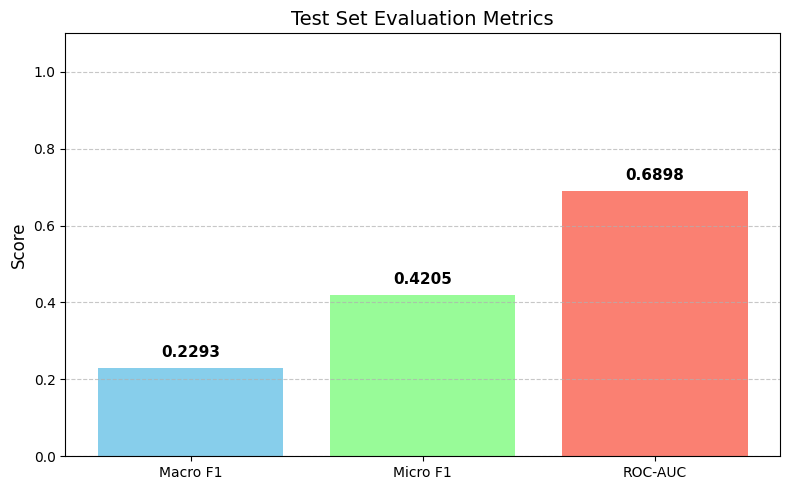

In [23]:

import torchvision.models as models
from sklearn.metrics import f1_score, roc_auc_score
from torch import optim
from tqdm import tqdm

# ==========================================
# Pretrained ResNet Initialization & Fine-Tuning
# ==========================================

# 1. Load a pre-trained ResNet model
# TODO: Initialize resnet18 with ImageNet weights
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)



for param in resnet_model.parameters():
    param.requires_grad = False

# Replace final layer
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_ftrs, num_genres)

# Unfreeze final layer
for param in resnet_model.fc.parameters():
    param.requires_grad = True


resnet_model = resnet_model.to(device)

# 3. Define Optimizer and Loss
# TODO: Use the same pos_weight_tensor calculated earlier to handle class imbalance
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = optim.Adam(resnet_model.parameters(), lr=0.001)

epochs_resnet = 10# Fewer epochs are usually needed for fine-tuning

train_losses_res = []
val_losses_res = []

print("Fine-tuning Pretrained ResNet...")
for epoch in range(epochs_resnet):
    resnet_model.train()
    running_loss = 0.0
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs_resnet} [Train]")

    for images, labels in progress_bar:
        images, labels = images.to(device), labels.to(device)

        # TODO: Perform the standard PyTorch training step:
        # Compute the forward pass, calculate the loss, backpropagate the error,
        # and update the model weights.
        optimizer.zero_grad()
        outputs = resnet_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        progress_bar.set_postfix({'batch_loss': loss.item()})

    train_losses_res.append(running_loss / len(train_dataset))
    resnet_model.eval()
    val_loss_res = 0.0

    # torch.no_grad() prevents PyTorch from storing gradients, saving memory during eval
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            # TODO: Compute the model's predictions,
            # and calculate the batch loss.
            outputs = resnet_model(images)
            loss = criterion(outputs, labels)
            # Loss update
            val_loss_res += loss.item() * images.size(0)

    val_loss_res = val_loss_res / len(val_dataset)
    val_losses_res.append(val_loss_res) # Store for plotting

    print(f"End of Epoch {epoch+1} | Val Loss: {val_loss_res:.4f}")



# ==========================================
# 1. Quantitative Evaluation
# ==========================================
resnet_model.eval()
all_targets_res = []
all_predictions_res = []
binary_predictions_res = []

print("Evaluating model on the Test Set (ML-Small)...")

# TODO:
# 1. Write the evaluation loop over `test_loader` (remember to disable gradients)
# 2. Apply the correct activation function to get probabilities.
# 3. Append the true labels to `all_targets` and probabilities to `all_predictions`.
# 4. Stack them into continuous 2D numpy arrays.
# 5. Create a `binary_predictions` array by thresholding probabilities at 0.5.

# --- YOUR EVALUATION LOOP HERE ---

# torch.no_grad() prevents PyTorch from storing gradients, saving memory during eval


with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
# 2. Apply the correct activation function to get probabilities.
            outputs = resnet_model(images)
            probabilities = torch.sigmoid(outputs)
            predictions = (probabilities > 0.5)
# 3. Append the true labels to `all_targets` and probabilities to `all_predictions`.
            all_targets_res.append(labels.cpu().numpy())
            all_predictions_res.append(probabilities.cpu().numpy())
            binary_predictions_res.append(predictions.cpu().numpy())


# 4. Stack them into continuous 2D numpy arrays.
all_targets_res = np.vstack(all_targets_res)
all_predictions_res = np.vstack(all_predictions_res)
binary_predictions_res = np.vstack(binary_predictions_res)


# TODO: Calculate the metrics.
# Hint: Pay attention to which metric needs binary predictions vs. continuous probabilities.
macro_f1_res = f1_score(all_targets_res, binary_predictions_res, average='macro')
micro_f1_res = f1_score(all_targets_res, binary_predictions_res, average='micro')
roc_auc_res = roc_auc_score(all_targets_res, all_predictions_res, average = 'macro')


# ==========================================
# --- VISUALIZE QUANTITATIVE METRICS ---
# ==========================================

metrics_dict_res = {'Macro F1': macro_f1_res, 'Micro F1': micro_f1_res, 'ROC-AUC': roc_auc_res}

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics_dict_res.keys(), metrics_dict_res.values(), color=['#87CEEB', '#98FB98', '#FA8072'])
plt.ylim(0, 1.1)
plt.title('Test Set Evaluation Metrics', fontsize=14)
plt.ylabel('Score', fontsize=12)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}',
             ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

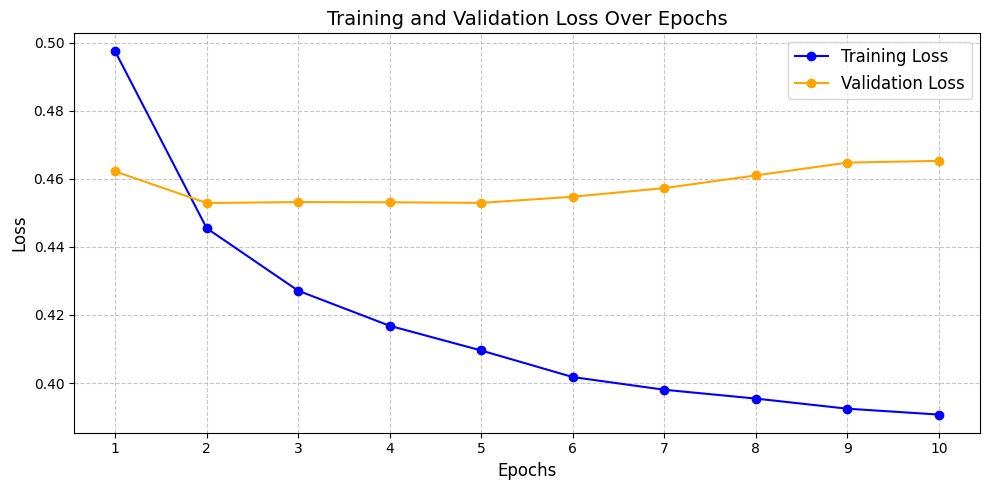

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs_resnet+1), train_losses_res, label='Training Loss', marker='o', color='blue')
plt.plot(range(1, epochs_resnet+1), val_losses_res, label='Validation Loss', marker='o', color='orange')
plt.title('Training and Validation Loss Over Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.xticks(range(1, epochs_resnet+1))
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Answer Below:

1. **Performance Comparison:** Compare the Macro F1 and ROC-AUC scores of your Custom CNN against the Pre-trained ResNet. Which model performed better, and by how much?

2. **Training Dynamics:** Look at the training and validation loss curves for both models. Did one model converge faster than the other? Did you notice any signs of overfitting in either model?

3. Why do you think the Pre-trained ResNet achieves these results compared to your Custom CNN, considering both models were trained on the exact same movie poster dataset?

1. ResNet18 had 0.2259 Macro-F1 score and 0.7003 ROC-AUC score while our custom CNN scored 0.1603 for Macro-F1 and 0.5932 for ROC-AUC. This means that the improvement in ResNet is 40% for Macro-F1 and 18% for ROC-AUC

2. The ResNet converged much faster. The custom CNN needed more than 10 epochs for the training loss to decrease significantly while the ResNet achieved that in only 6 epochs. The overfitting for the custom CNN started to increase dramatically after 10 epochs while for the ResNet it beggined much earlier but it is more gradual.

3. 
4. The ResNet performed better because of transfer learning. The model is already pretrained in a dataset with millions of images and has better ability to extract features and also has deeper and more optimized architecture

---
### **Extract Visual Embeddings**


Now that you have trained both a Custom CNN and a Pre-trained ResNet to understand movie genres based on visual features, we want to extract that "visual understanding" to use in our recommendation system graph (Task 3).

**Look back at your evaluation metrics (F1 Score, ROC-AUC) and choose the model that achieved the BEST overall results.**

Instead of getting the final genre predictions (the raw logits), we will pass the posters from the  `ml-latest-small` dataset through your chosen model and stop at the **penultimate layer**. This gives us a dense feature vector (embedding) for every single movie. (Note: The size of this vector will depend on the model you chose—for example, a standard ResNet18 outputs a 512-dimensional vector).

Ensure the order of the embeddings perfectly matches the dataframe! Save the resulting tensor to a `.pt` (PyTorch) file so it can be easily loaded in Task 3.


In [25]:
import torch
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm

# TODO: 1. Choose your best model (e.g., cv_model or resnet_model)
best_vision_model = cv_model
best_vision_model.to(device)

# Setup DataLoader (CRITICAL: shuffle MUST be False to match embeddings to movieIds!)
inference_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Set the chosen model to evaluation mode
best_vision_model.eval()
all_embeddings = []

print(f"Extracting embeddings for {len(test_dataset)} movies...")

# TODO: 2. Write the extraction loop
# - Loop over the images in `inference_loader`.
# - Extract the corresponding embeddings.
# - Move the resulting embeddings back to `.cpu()` and append them to the `all_embeddings` list.

# --- YOUR EXTRACTION LOOP HERE ---

with torch.no_grad():                          # Disable gradient computation
    for images, _ in tqdm(inference_loader):   # _ discards labels
        images = images.to(device)
        embeddings = best_vision_model.extract_embeddings(images) # Now outputs (batch, 512)
        all_embeddings.append(embeddings.cpu()) # Move back to CPU


# ---------------------------------

# Concatenate all batches into a single large tensor
final_visual_embeddings = torch.cat(all_embeddings, dim=0)
print(f"Extracted Embeddings Shape: {final_visual_embeddings.shape} -> [Num_Movies, Embedding_Dim]")

# ==========================================
# --- SAVING BOILERPLATE ---
# (Do not modify the code below this line)
# ==========================================
save_dict = {
    'movie_ids': torch.tensor(small_full['movieId'].values),
    'embeddings': final_visual_embeddings
}

torch.save(save_dict, 'datasets/cv_embeddings.pt')
print("Visual embeddings successfully saved to 'datasets/cv_embeddings.pt'!")

Extracting embeddings for 9617 movies...


  0%|          | 0/301 [00:00<?, ?it/s]

Extracted Embeddings Shape: torch.Size([9617, 6400]) -> [Num_Movies, Embedding_Dim]
Visual embeddings successfully saved to 'datasets/cv_embeddings.pt'!


---
## **Task 2: Natural Language Processing for Genre Classification**

In this task, you will tackle the exact same multi-label classification problem, but using a completely different modality: **Text**. You will build a sequence model (RNN, LSTM, or GRU) to predict genres based on the movie's plot summary (the `overview` column).

To make this model more powerful and interpretable, you are required to implement a **Custom Attention Mechanism**.

### **Text Preprocessing & Data Loading**
Unlike images, neural networks cannot process raw text. We must convert the words into numerical tokens. Below, we provide the pipeline to:
1. Clean and tokenize the text.
2. Build a Vocabulary based solely on the training set (to avoid data leakage).
3. Convert summaries into padded numerical tensors.

In [ ]:
# Assuming datasets.zip is in the root of your Google Drive
!unzip -o /content/drive/MyDrive/datasets.zip -d datasets/

In [26]:
import pickle as pkl

# load pre-saved pickled dataframes, if needed
train_df = pkl.load(open('train_df.pkl', 'rb'))
val_df = pkl.load(open('val_df.pkl', 'rb'))

A tokenizer is essentially the "translator" that turns a raw blob of text into a format a machine can actually digest.

Complete the simple tokenizer, as instructed below.

In [27]:
import re
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

# Simple Tokenizer, returns a list of strings
def tokenize(text):
    """Lowercases, removes punctuation, and splits by whitespace."""
    # TODO
    # 1. Convert the input text to a lowercase string.
    text = text.lower()
    # 2. Use regex to remove any character that isn't a letter, number, or whitespace.
    text = re.sub(r'[^\w\s]', '', text)
    # 3. Split the cleaned string into a list of individual words (tokens).
    tokens = text.split()
    return tokens
    # --- YOUR CODE HERE ---



    # ----------------------


# Build Vocabulary from Training Set ONLY
print("Building vocabulary...")
all_tokens = []
for plot in train_df['overview']:
    all_tokens.extend(tokenize(plot))

Building vocabulary...


We need to build a mapping of the words within the plot summaries. We select our vocabulary to contain the top 10,000 most frequent words and map them to unique IDs. It reserves 0 for padding and 1 for unknown words (the rare ones we excluded). Raw text needs to be converted into fixed-length numerical vectors (here, set to 150 tokens), truncating long sequences and padding short ones to ensure uniform input for the model.

In [28]:
# Keep top 10,000 most common words, reserve 0 for <PAD> and 1 for <UNK>

max_vocab_size = 10000
vocab_counts = Counter(all_tokens)
vocab = {word: idx + 2 for idx, (word, _) in enumerate(vocab_counts.most_common(max_vocab_size))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def text_to_tensor(text, vocab, max_len=150):
    """Converts a text string to a padded tensor of token IDs."""
    tokens = tokenize(text)
    token_ids = [vocab.get(word, vocab['<UNK>']) for word in tokens]

    # Truncate if too long
    if len(token_ids) > max_len:
        token_ids = token_ids[:max_len]

    # Pad if too short
    pad_len = max_len - len(token_ids)
    token_ids = token_ids + [vocab['<PAD>']] * pad_len

    return torch.tensor(token_ids, dtype=torch.long)

And we will build a pytorch dataset like before.

In [29]:
class MoviePlotDataset(Dataset):
    def __init__(self, dataframe, vocab):
        self.dataframe = dataframe.reset_index(drop=True)
        self.vocab = vocab
        self.label_cols = self.dataframe.columns[6:].tolist()

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        plot_text = self.dataframe.loc[idx, 'overview']
        text_tensor = text_to_tensor(plot_text, self.vocab)

        # Extract labels
        labels = self.dataframe.loc[idx, self.label_cols].values.astype(float)
        labels = torch.tensor(labels, dtype=torch.float32)

        return text_tensor, labels

In [30]:
print("Initializing NLP Datasets...")
nlp_train_dataset = MoviePlotDataset(train_df, vocab)
nlp_val_dataset = MoviePlotDataset(val_df, vocab)
nlp_test_dataset = MoviePlotDataset(small_full, vocab)

Initializing NLP Datasets...


In [31]:
batch_size = 32
nlp_train_loader = DataLoader(nlp_train_dataset, batch_size=batch_size, shuffle=True)
nlp_val_loader = DataLoader(nlp_val_dataset, batch_size=batch_size, shuffle=False)
nlp_test_loader = DataLoader(nlp_test_dataset, batch_size=batch_size, shuffle=False)

# Test the dataloader
print("For training...")
sample_texts, sample_labels = next(iter(nlp_train_loader))
print(f"Text Batch Shape: {sample_texts.shape} -> [Batch, Sequence_Length]")
print(f"Label Batch Shape: {sample_labels.shape} -> [Batch, Num_Genres]")

For training...
Text Batch Shape: torch.Size([32, 150]) -> [Batch, Sequence_Length]
Label Batch Shape: torch.Size([32, 20]) -> [Batch, Num_Genres]


---
### **Architecture with Custom Attention**

You must build a deep learning text classifier. You may choose the recurrent backbone (e.g., `nn.RNN`, `nn.GRU`, or `nn.LSTM`).

However, instead of simply passing the final hidden state to your classification head, you must implement a **Self-Attention Mechanism** to compute a weighted context vector from *all* the hidden states of your sequence.

**A simple Attention Mechanism:**
Given the hidden states of your RNN layer $H = [h_1, h_2, ..., h_T]$:
1. Calculate the attention scores for each token: $e_t = \text{Linear}(h_t)$
2. Compute the normalized attention weights using Softmax: $\alpha = \text{softmax}(e)$
3. Compute the final context vector by taking the weighted sum of the hidden states: $c = \sum_{t=1}^{T} \alpha_t h_t$


In [90]:

In the following code, you will need to:
1. Define an `nn.Embedding` layer.
2. Define your recurrent layer (`batch_first=True` is recommended).
3. Implement the attention mechanism in the `forward` pass.
4. Pass the resulting context vector $c$ to a fully connected layer to output your unnormalized logits.
5. Implement the `extract_embeddings` function to return the context vector $c$.

SyntaxError: invalid syntax (4060215688.py, line 1)

In [41]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

In [139]:
import torch.nn as nn
import torch.nn.functional as F

class CustomTextClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super(CustomTextClassifier, self).__init__()

        # TODO: Define your layers
        # 1. Embedding layer: map vocab_size to embed_dim (don't forget padding_idx=0)
        # 2. RNN layer: set batch_first=True
        # 3. Attention Projection: a Linear layer mapping hidden_dim to a single score (1)
        # 4. Classifier Head: a Linear layer mapping hidden_dim to num_classes

        # --- YOUR LAYERS HERE ---
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional = True)

        self.attention_proj = nn.Linear(hidden_dim*2, 1)

        self.fc = nn.Linear(hidden_dim*2, num_classes)
        # ------------------------


    def forward(self, x):

       # TODO: Implement the Attention-based Forward Pass
        # 1. Pass input through the embedding layer.
        embeddings = self.embedding(x)
        # 2. Pass embeddings through the RNN. Get all hidden states 'H'.
        H, _ = self.rnn(embeddings)
        # 3. Calculate energy scores 'e'
        e = self.attention_proj(H)
        # 4. Calculate attention weights 'alpha'.
        a = F.softmax(e, dim=1)
        # 5. Calculate the context vector 'c'.
        c = torch.sum(a*H,dim=1)
        # 6. Pass the context vector through the final classifier to get logits.
        logits = self.fc(c)

        # --- YOUR FORWARD PASS HERE ---

        return logits
        # ------------------------------



    def extract_embeddings(self, x):
        """Returns the final context vector 'c' BEFORE the classification head."""
        # TODO: Replicate the forward pass logic above, but STOP after calculating
        # the context vector 'c'. Return 'c' as the embedding.

        # --- YOUR EXTRACTION HERE ---
        embeddings = self.embedding(x)
        H, _ = self.rnn(embeddings)
        e = self.attention_proj(H)
        a = F.softmax(e,dim=1)
        c = torch.sum(a*H,dim=1)

        return c
        # ----------------------------

In [141]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Model will be initialized in {device}.\n")

vocab_size = len(vocab)
embed_dim = 128
hidden_dim = 256
num_classes = len(nlp_train_dataset.label_cols)

nlp_model = CustomTextClassifier(vocab_size, embed_dim, hidden_dim, num_classes).to(device)
print(nlp_model)

Model will be initialized in cuda.

CustomTextClassifier(
  (embedding): Embedding(10002, 128, padding_idx=0)
  (rnn): GRU(128, 256, batch_first=True, bidirectional=True)
  (attention_proj): Linear(in_features=512, out_features=1, bias=True)
  (fc): Linear(in_features=512, out_features=20, bias=True)
)


---
### **Training & Evaluation Loop**

You already know how to train and evaluate a PyTorch model!

1. Write the training loop.
2. Remember to use the `pos_weight` tensor we calculated in Task 1 to handle the class imbalance.
3. Plot the Training and Validation loss curves.
4. Evaluate the model on ML-Small summaries using Macro/Micro F1-Scores.

Epoch 1/20 - Train Loss: 0.5356, Val Loss: 0.4887
Epoch 2/20 - Train Loss: 0.4901, Val Loss: 0.4808
Epoch 3/20 - Train Loss: 0.4817, Val Loss: 0.4740
Epoch 4/20 - Train Loss: 0.4712, Val Loss: 0.4651
Epoch 5/20 - Train Loss: 0.4579, Val Loss: 0.4592
Epoch 6/20 - Train Loss: 0.4449, Val Loss: 0.4544
Epoch 7/20 - Train Loss: 0.4352, Val Loss: 0.4522
Epoch 8/20 - Train Loss: 0.4262, Val Loss: 0.4468
Epoch 9/20 - Train Loss: 0.4171, Val Loss: 0.4427
Epoch 10/20 - Train Loss: 0.4083, Val Loss: 0.4503
Epoch 11/20 - Train Loss: 0.4002, Val Loss: 0.4469
Epoch 12/20 - Train Loss: 0.3921, Val Loss: 0.4492
Epoch 13/20 - Train Loss: 0.3828, Val Loss: 0.4464
Epoch 14/20 - Train Loss: 0.3742, Val Loss: 0.4428
Epoch 15/20 - Train Loss: 0.3661, Val Loss: 0.4515
Epoch 16/20 - Train Loss: 0.3577, Val Loss: 0.4469
Epoch 17/20 - Train Loss: 0.3489, Val Loss: 0.4447
Epoch 18/20 - Train Loss: 0.3408, Val Loss: 0.4538
Epoch 19/20 - Train Loss: 0.3324, Val Loss: 0.4558
Epoch 20/20 - Train Loss: 0.3256, Val Lo

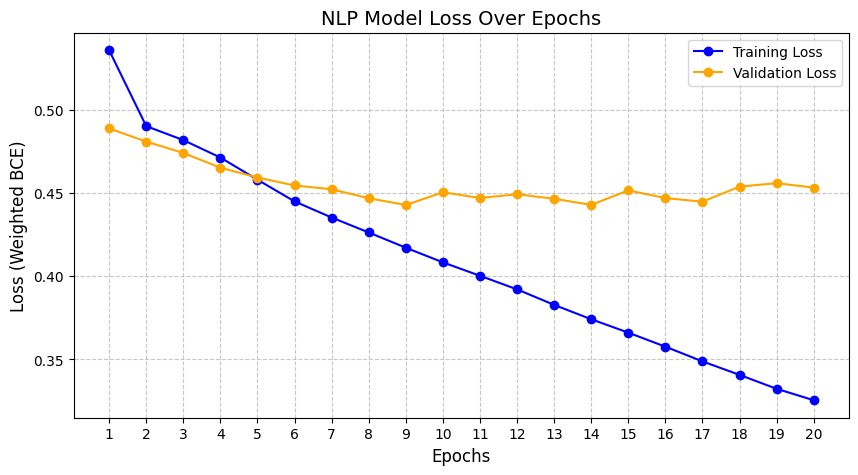

In [142]:
import torch.optim as optim
from tqdm.notebook import tqdm

# --- 1. SETUP ---
# TODO: Initialize the loss criterion and optimizer (use pose_weight)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = optim.Adam(nlp_model.parameters(), lr=0.0001)

epochs = 20
train_losses = []
val_losses = []

# --- 2. TRAINING & VALIDATION LOOP ---
for epoch in range(epochs):
    # --- TRAINING PHASE ---
    nlp_model.train()
    running_train_loss = 0.0
    

    # TODO: Implement the training loop
    # 1. Iterate over train_loader
    for sample_texts, sample_labels in nlp_train_loader:
    # 2. Forward pass, Calculate Loss, Backward pass, Optimizer step
        sample_texts = sample_texts.long().to(device)
        sample_labels = sample_labels.float().to(device)
        optimizer.zero_grad()
        outputs = nlp_model(sample_texts)
        loss = criterion(outputs, sample_labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(nlp_model.parameters(), max_norm=1.0)
        optimizer.step()
    # Optional: Use gradient clipping to prevent expoding gradients (common in RNNs)
        running_train_loss += loss.item()

    train_loss = running_train_loss / len(nlp_train_loader)

    # --- VALIDATION PHASE ---
    nlp_model.eval()
    running_val_loss = 0.0

    # TODO: Implement the validation loop (remember torch.no_grad())
    # 1. Iterate over val_loader
    # 2. Forward pass, Calculate Loss
    with torch.no_grad():
        for sample_texts, sample_labels in nlp_val_loader:
            sample_texts = sample_texts.long().to(device)
            sample_labels = sample_labels.float().to(device)
            outputs = nlp_model(sample_texts)

            loss = criterion(outputs, sample_labels)

            running_val_loss += loss.item()

    val_loss = running_val_loss / len(nlp_val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)


    # Save average losses for plotting
    # train_losses.append(...)
    # val_losses.append(...)

    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")



# ==========================================
# --- VISUALIZATION LOSS CURVES ---
# (Do not modify the code below this line)
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs+1), train_losses, label='Training Loss', marker='o', color='blue')
plt.plot(range(1, epochs+1), val_losses, label='Validation Loss', marker='o', color='orange')
plt.title('NLP Model Loss Over Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss (Weighted BCE)', fontsize=12)
plt.xticks(range(1, epochs+1))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


Evaluating on Test Set...
Test Macro F1-Score: 0.2571
Test Micro F1-Score: 0.4089


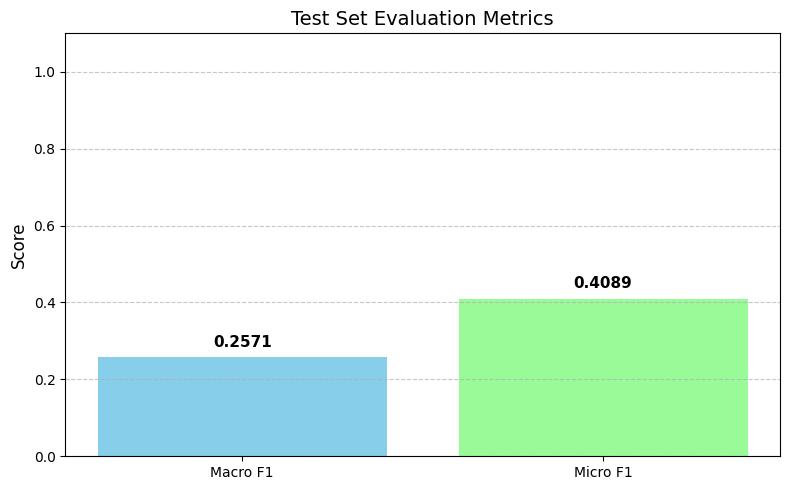

In [143]:
# --- 3. EVALUATION N TEST SET (ML-Small) ---
# TODO: Evaluate on the test set
# - Generate predictions for the test_loader
# - Apply Sigmoid and 0.5 threshold
# - Calculate Macro/Micro F1 using sklearn

from sklearn.metrics import f1_score

print("\nEvaluating on Test Set...")

# --- YOUR CODE  HERE ---
nlp_model.eval()

all_labels_nlp = []
all_predictions_nlp = []

with torch.no_grad():
    for sample_texts, sample_labels in nlp_test_loader:
        sample_texts = sample_texts.long().to(device)
        sample_labels = sample_labels.float().to(device)
        outputs = nlp_model(sample_texts)

        probs = torch.sigmoid(outputs)
        preds = (probs >= 0.5).float()
        all_predictions_nlp.append(preds.cpu().numpy())
        all_labels_nlp.append(sample_labels.cpu().numpy())


all_labels_nlp = np.vstack(all_labels_nlp)
all_predictions_nlp = np.vstack(all_predictions_nlp)

# ----------------------

macro_f1 = f1_score(all_labels_nlp, all_predictions_nlp, average='macro')
micro_f1 = f1_score(all_labels_nlp, all_predictions_nlp, average = 'micro')

print(f"Test Macro F1-Score: {macro_f1:.4f}")
print(f"Test Micro F1-Score: {micro_f1:.4f}")


metrics_dict_nlp = {'Macro F1': macro_f1, 'Micro F1': micro_f1}

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics_dict_nlp.keys(), metrics_dict_nlp.values(), color=['#87CEEB', '#98FB98', '#FA8072'])
plt.ylim(0, 1.1)
plt.title('Test Set Evaluation Metrics', fontsize=14)
plt.ylabel('Score', fontsize=12)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}',
             ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

---
### **Extract NLP Embeddings for Task 3**

Just like in Task 1, we need to extract the semantic "understanding" of the plots to use as node features in our GNN and save them in `nlp_embeddings.pt`.


In [35]:
# TODO: Extract semantic text embeddings using your trained `nlp_model`
# 1. Create a list named `all_nlp_embeddings` to store batch results.
# 2. Write a loop over `nlp_test_loader` without tracking gradients to extract the embeddings.
# 3. Move the resulting embeddings back to the CPU and append them to your list.
# 4. Combine all batches into a single tensor named `final_nlp_embeddings`.

# --- YOUR EXTRACTION LOOP HERE ---
nlp_model.eval()
all_nlp_embeddings = []
final_nlp_embeddings = []
with torch.no_grad():
    for sample_texts, _ in nlp_test_loader:
        sample_texts = sample_texts.long().to(device)
        embeddings = nlp_model.extract_embeddings(sample_texts)
        all_nlp_embeddings.append(embeddings.cpu()) 

# ---------------------------------

# Concatenate all batches into a single large tensor
final_nlp_embeddings = torch.cat(all_nlp_embeddings, dim=0)
        

# ---------------------------------


# ==========================================
# --- SAVING ---
# (Do not modify the code below this line)
# ==========================================
print(f"Extracted NLP Embeddings Shape: {final_nlp_embeddings.shape} -> [Num_Movies, Hidden_Dim]")

save_dict = {
    'movie_ids': torch.tensor(small_full['movieId'].values),
    'embeddings': final_nlp_embeddings
}

torch.save(save_dict, 'datasets/nlp_embeddings.pt')
print("Semantic NLP embeddings successfully saved to 'datasets/nlp_embeddings.pt'!")

Extracted NLP Embeddings Shape: torch.Size([9617, 512]) -> [Num_Movies, Hidden_Dim]
Semantic NLP embeddings successfully saved to 'datasets/nlp_embeddings.pt'!


---
### **Questions**

1. **Modality Comparison:** Look at your final F1-scores. Did the NLP model (Plot Summaries) or the CV model (Movie Posters) perform better at predicting genres? Why do you think that modality was more successful?
3. **Attention Interpretability:** One of the main benefits of the Attention mechanism is interpretability. If you were to visualize the attention weights ($\alpha$) for the summary *"A lone cowboy rides into a dusty town to face the outlaw,"* which words do you expect would receive the highest attention weights when predicting the "Western" genre?
4. **Sequence Length:** We capped the `max_len` at 150 words and padded shorter sequences with 0s. How might processing very long padding sequences negatively affect an RNN's performance, and how does the Attention mechanism help mitigate this issue?

Answers
1. The NLP model performed better at predicting genres. This is because it is easier to extract semantic information for the story and the characters from words. In constrast, posters can be more ambiguous and stylistic rather than descriptive.
2. For the summary "A lone cowboy rides into a dusty town to face the outlaw" I would choose the words cowboy, town and outlaw to have the highest attention weights as these are very common characteristics in Western movies.
3. Very long padding sequences provide no additional information and make the model to forget earlier important words. The attention mechanism helps mitigate this issue by allowing the model to learn and focus on the most important words in the sentence regardless their position.

---
### Optimizations
---

Your initial F1-scores are likely low. Training an NLP model from scratch on only 15,000 short summaries is difficult, especially with severe class imbalance. If you want to extract higher-quality semantic embeddings for Task 3, try implementing **some** of these upgrades:

**1. Increased epochs, hyperparameter tuning**

**3. Bidirectional RNNs**: Learn from left to right and right to left.
This gives your Attention mechanism much better context to work with.

**3. Pre-trained Word Embeddings (GloVe)**
Instead of forcing your `nn.Embedding` layer to learn the meaning of words from scratch, you can load pre-trained GloVe weights `torchtext.vocab.GloVe` (Global Vectors for Word Representation). This gives your model an immediate, massive understanding of the English language.

**4. Dynamic Thresholding**


In [ ]:
#TODO

---
## **Task 3: Graph Neural Networks for Link Prediction**


In this final task, you will build a recommendation system. You will construct a **Bipartite Heterogeneous Graph** consisting of `User` nodes and `Movie` nodes, connected by `rates` edges.

The goal is **Link Prediction**: predicting the probability that a specific User will rate a specific Movie.

Instead of writing the complex GNN layers from scratch, the architecture and training loop are provided for you. You must engineer the node features using the embeddings you extracted in Tasks 1 & 2, format the graph data, and perform an ablation study to explain *why* multimodal features improve recommendation systems.



---
### **Graph Construction**
Graph frameworks require node IDs to be contiguous integers starting from $0$. MovieLens IDs (like `movieId = 5000`) will cause out-of-bounds errors if not mapped properly. The code below loads the ratings and creates mappings.

In [ ]:
!unzip -o /content/drive/MyDrive/datasets.zip -d datasets/

In [36]:
import torch
import os

print("Installing PyTorch Geometric base...")
!pip install -q torch-geometric

print("Attempting to install optional C++ speedups (this may take a minute)...")
torch_version = torch.__version__.split('+')[0]
cuda_version = torch.version.cuda.replace('.', '')
whl_url = f"https://data.pyg.org/whl/torch-{torch_version}+cu{cuda_version}.html"

# We use > /dev/null to hide the scary red text if the wheels aren't compiled for Colab's newest PyTorch version yet.
# Our GNN will run perfectly fine on the base library!
os.system(f"pip install -q pyg_lib torch_scatter torch_sparse -f {whl_url} > /dev/null 2>&1")

print("PyTorch Geometric environment ready!")

Installing PyTorch Geometric base...
Attempting to install optional C++ speedups (this may take a minute)...
PyTorch Geometric environment ready!


In [82]:
import torch
import pandas as pd
import numpy as np
from torch_geometric.data import HeteroData
import torch_geometric.transforms as T

# Load the ratings data from the small graph
ratings_df = pd.read_csv('datasets/datasets/ml-latest-small/ratings.csv')

# Only keep ratings for movies that exist in our valid small_full set (with TMDB links)
small_full = pd.read_csv('datasets/datasets/ml_small_metadata_full.csv')
valid_movie_ids = set(small_full['movieId'])
ratings_df = ratings_df[ratings_df['movieId'].isin(valid_movie_ids)]

# Create Contiguous IDs for Users and Movies
unique_users = ratings_df['userId'].unique()
unique_movies = small_full['movieId'].unique() # Use the full valid subset, not just rated ones

user_mapping = {userid: i for i, userid in enumerate(unique_users)}
movie_mapping = {movieid: i for i, movieid in enumerate(unique_movies)}

# Map the edges
src = [user_mapping[uid] for uid in ratings_df['userId']]
dst = [movie_mapping[mid] for mid in ratings_df['movieId']]
edge_index = torch.tensor([src, dst], dtype=torch.long)

print(f"Total Users: {len(user_mapping)}")
print(f"Total Movies: {len(movie_mapping)}")
print(f"Total Ratings (Edges): {edge_index.shape[1]}")

Total Users: 610
Total Movies: 9617
Total Ratings (Edges): 100511


---
### **Feature Engineering & Initialization**

A GNN relies on its starting node features. Because we don't have metadata for the users (like age or gender), we will initialize user nodes with random learnable embeddings. For the movies, you will test different feature combinations.

1. Load your saved `cv_embeddings.pt` and `nlp_embeddings.pt`.
2. Ensure the order of the embeddings matches the contiguous `movie_mapping` (hint: they should already match if you used `small_full` sequentially!).
3. Initialize the PyG `HeteroData` object.
4. Experiment with different movie feature initializations:
   * **Baseline:** Dummy features (e.g., `torch.ones` or random noise).
   * **Unimodal:** Only CV features, or only NLP features.
   * **Multimodal Concatenation:** Concatenate CV and NLP features (`torch.cat`).
   * **Pretrained:** We have provided a file of pre-trained and fine-tuned (on the train_df movie plots) DistilBERT embeddings.

Load your saved `cv_embeddings.pt` and `nlp_embeddings.pt`.

In [38]:
cv_data = torch.load('datasets/cv_embeddings.pt')
cv_features = cv_data['embeddings'] # Shape: [Num_Movies, 512]

nlp_data = torch.load('datasets/nlp_embeddings.pt')
nlp_features = nlp_data['embeddings'] # Shape: [Num_Movies, 256]

Ensure the order of the embeddings matches the contiguous `movie_mapping`. They should already match if you used `small_full` sequentially

You can just use the provided embeddings to complete this task, if you could not complete the previous tasks successfully or the embeddings created were not great representations of the data (this will not affect your grade).

**Important:** make sure to normalize the extracted features! CV and NLP embeddings are raw outputs from custom networks and their range will blow up the gradients.

In [39]:
import torch.nn.functional as F

def get_movie_features(strategy, cv_feats, nlp_feats, num_movies):
    """Returns the appropriate node feature tensor based on the selected ablation strategy."""
    if strategy == "baseline":
        return torch.randn((num_movies, 64))

    elif strategy == "cv":
        # TODO: Return the L2-normalized visual embeddings from Task 1
        return F.normalize(cv_features, p=2)
        
    elif strategy == "nlp":
         # TODO: Return the L2-normalized visual embeddings from Task 1
        return F.normalize(nlp_features,p=2)

    elif strategy == "multimodal":
         # TODO: Concatenate the CV and NLP features,
         # then apply L2-normalization to the combined vector.
        return F.normalize(torch.cat([cv_features,nlp_features],dim=1),p=2)

    elif strategy == "pretrained":
         # TODO: Load the 'pretrained_nlp_embeddings.pt' file and return the normalized embeddings.
        pretrained_features = torch.load('datasets/pretrained_nlp_embeddings.pt')
        return F.normalize(pretrained_features, p=2)

    else:
        raise ValueError("Invalid strategy! Please choose 'baseline', 'cv', 'nlp', 'multimodal', or 'pretrained'.")

This function transforms raw data into a **Bipartite Heterogeneous Graph**. In high-level terms, it sets up the "map" that the GNN will use to navigate and learn.

* **`HeteroData()`**: Instead of a simple list, we initialize a specialized container that recognizes different "species" of nodes (Users vs. Movies) and their specific relationships.
* **User Nodes (Structural IDs)**: We tell the graph how many users exist. Since we have no metadata for them, the GNN will later assign them unique, learnable "fingerprints" (embeddings) based purely on their position in the graph.
* **Movie Nodes (Semantic Features)**: Unlike users, movies are initialized with the rich features you extracted (CV/NLP). This allows the GNN to understand *what* a movie is, rather than just knowing its ID.
* **Edge Index (The Connections)**: This maps the "rates" relationship. It acts as the bridge that tells the model which users interacted with which movies.
* **`T.ToUndirected()` (Two-Way Communication)**: By default, a rating is one-way (User $\to$ Movie). This transform creates "reverse" edges so that information can flow from movies back to users, allowing the GNN to perform complex message passing.

In [40]:
from torch_geometric.data import HeteroData
import torch_geometric.transforms as T

def build_graph(movie_features):
    data = HeteroData()

    # User nodes just need to know how many exist
    data['user'].num_nodes = len(user_mapping)

    # Movie nodes require the actual semantic features
    data['movie'].x = movie_features

    # Add Edges
    data['user', 'rates', 'movie'].edge_index = edge_index

    # GNNs need undirected paths to pass messages back and forth
    data = T.ToUndirected()(data)

    return data

---
### **GNN Architecture and Training**

Below is a complete implementation of a Heterogeneous Graph Neural Network using `GraphSAGE` ([paper](https://arxiv.org/abs/1706.02216)).

Imagine you are trying to represent a specific movie, let's say *The Matrix*.
1. **Initial State:** You start with the movie's own features (the CV poster embedding and the NLP plot embedding you gave it).
2. **Sampling:** GraphSAGE looks at the graph and randomly *samples* a few neighboring nodes. For a movie, its neighbors are the **Users** who rated it.
3. **Aggregating** It asks those neighboring Users, *"What else do you like?"* It pulls in the features of the *other* movies those users watched, mathematically averages (or pools) them together, and uses that new information to update the embedding for *The Matrix*.

By layer 2 of your GNN, the embedding for a User is no longer just random noise. It has been updated to represent a combination of all the CV posters and NLP plots of the movies they have watched! The GNN learns to say: *"User A tends to click on movies with dark, blue-tinted posters (CV) and plots involving space travel (NLP)."* When the Decoder compares User A to a new sci-fi movie, the dot product of their embeddings will be very high, resulting in a successful recommendation!

Specifically:
* **The Encoder:** Two layers of message passing. It aggregates features from neighboring nodes to create rich, relational embeddings for both users and movies.
* **The Decoder (Link Predictor):** To predict if an edge exists, we take the final GNN embedding of a User ($z_u$) and a Movie ($z_v$), and compute their dot product: $\hat{y} = z_u \cdot z_v$. We then pass this through a Sigmoid to get a probability.

In [46]:
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv, HeteroConv

class HeteroGNNEncoder(nn.Module):
    def __init__(self, hidden_channels, out_channels):
        super().__init__()
        # HeteroConv allows us to define specific message passing for specific edge types.
        self.conv1 = HeteroConv({
            ('user', 'rates', 'movie'): SAGEConv((-1, -1), hidden_channels),
            ('movie', 'rev_rates', 'user'): SAGEConv((-1, -1), hidden_channels),
        }, aggr='sum')

        self.conv2 = HeteroConv({
            ('user', 'rates', 'movie'): SAGEConv((-1, -1), out_channels),
            ('movie', 'rev_rates', 'user'): SAGEConv((-1, -1), out_channels),
        }, aggr='sum')

    def forward(self, x_dict, edge_index_dict):
        x_dict = self.conv1(x_dict, edge_index_dict)
        x_dict = {key: F.relu(x) for key, x in x_dict.items()}
        x_dict = self.conv2(x_dict, edge_index_dict)
        return x_dict


class EdgeDecoder(nn.Module):
    def __init__(self, hidden_channels):
        super().__init__()
        # Decodes the probability of a link by concatenating User and Movie embeddings
        self.lin1 = nn.Linear(2 * hidden_channels, hidden_channels)
        self.lin2 = nn.Linear(hidden_channels, 1)

    def forward(self, z_dict, edge_label_index):
        row, col = edge_label_index
        # Get the embeddings for the source (User) and destination (Movie)
        z = torch.cat([z_dict['user'][row], z_dict['movie'][col]], dim=-1)
        z = F.relu(self.lin1(z))
        z = self.lin2(z)
        return z.view(-1)


class RecommenderGNN(nn.Module):
    def __init__(self, hidden_channels, num_users, movie_feature_dim):
        super().__init__()
        # 1. Structural Embedding for Users (They have no metadata)
        self.user_emb = nn.Embedding(num_users, hidden_channels)

        # 2. Projection Layer for Movies
        self.movie_proj = nn.Linear(movie_feature_dim, hidden_channels)

        self.encoder = HeteroGNNEncoder(hidden_channels, hidden_channels)
        self.decoder = EdgeDecoder(hidden_channels)

    def forward(self, x_dict, edge_index_dict, edge_label_index):
        # Initialize node representations
        h_dict = {
            'user': self.user_emb.weight,
            'movie': self.movie_proj(x_dict['movie'])
        }

        # Pass through GraphSAGE layers
        z_dict = self.encoder(h_dict, edge_index_dict)

        # Decode the requested edges
        return self.decoder(z_dict, edge_label_index)

In Tasks 1 and 2, you used **inductive learning**: your CNN and RNN were trained on one set of data and evaluated on completely unseen, isolated test data.

Graph machine learning often relies on **transductive learning**.
* In a transductive setup, the model sees the *entire graph structure* (all User and Movie nodes) during the training phase.
* Because we can't easily isolate nodes without breaking the graph, we split **edges** instead of nodes.
* We hide a percentage of the "rates" edges to serve as our test set. The model learns by passing messages across the visible training edges, and we evaluate it by asking it to predict the existence of the edges we hid.

Regarding T.RandomLinkSplit:
* **`num_val=0.1` and `num_test=0.1`**: We hide 10% of the rating edges for validation and 10% for final testing. The remaining 80% are our training edges.
* **`disjoint_train_ratio=0.3`**: This is a crucial defense against data leakage. Of our 80% training edges, we separate them into two buckets. 70% are strictly used for **message passing** (building the node embeddings). The other 30% are used strictly as **supervision targets** (calculating the loss). If we let the GNN pass messages over the exact same edge it is trying to predict, it would be cheating!

In [47]:
import torch
import torch.nn.functional as F
from torch_geometric.data import HeteroData
import torch_geometric.transforms as T
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

# --- TRAINING & EVALUATION LOOP ---
def train_and_evaluate_graph(graph_data, num_epochs=40, hidden_channels=64, lr=0.01):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Create Train/Val/Test Link Splits (Negative Sampling)
    transform = T.RandomLinkSplit(
        num_val=0.1,
        num_test=0.1,
        disjoint_train_ratio=0.3,
        neg_sampling_ratio=1.0,
        add_negative_train_samples=True,
        edge_types=[('user', 'rates', 'movie')],
        rev_edge_types=[('movie', 'rev_rates', 'user')]
    )

    train_data, val_data, test_data = transform(graph_data)
    train_data, val_data = train_data.to(device), val_data.to(device)

    movie_feature_dim = graph_data['movie'].x.shape[1]
    num_users = graph_data['user'].num_nodes

    # Initialize Model
    model = RecommenderGNN(hidden_channels, num_users, movie_feature_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = torch.nn.BCEWithLogitsLoss()

    history = {'loss': [], 'val_auc': []}

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()

        out = model(train_data.x_dict,
                    train_data.edge_index_dict,
                    train_data['user', 'rates', 'movie'].edge_label_index)

        target = train_data['user', 'rates', 'movie'].edge_label.float()
        loss = criterion(out, target)
        loss.backward()
        optimizer.step()

        history['loss'].append(loss.item())

        # Validation
        model.eval()
        with torch.no_grad():
            val_out = model(val_data.x_dict,
                            val_data.edge_index_dict,
                            val_data['user', 'rates', 'movie'].edge_label_index)

            val_pred = torch.sigmoid(val_out).cpu().numpy()
            val_target = val_data['user', 'rates', 'movie'].edge_label.cpu().numpy()

            val_auc = roc_auc_score(val_target, val_pred)
            history['val_auc'].append(val_auc)

    return history, model



In [48]:
num_movies = len(movie_mapping)
strategies = ['baseline', 'cv', 'nlp', 'multimodal', 'pretrained']

Training Strategy: BASELINE
Training Strategy: CV
Training Strategy: NLP
Training Strategy: MULTIMODAL
Training Strategy: PRETRAINED


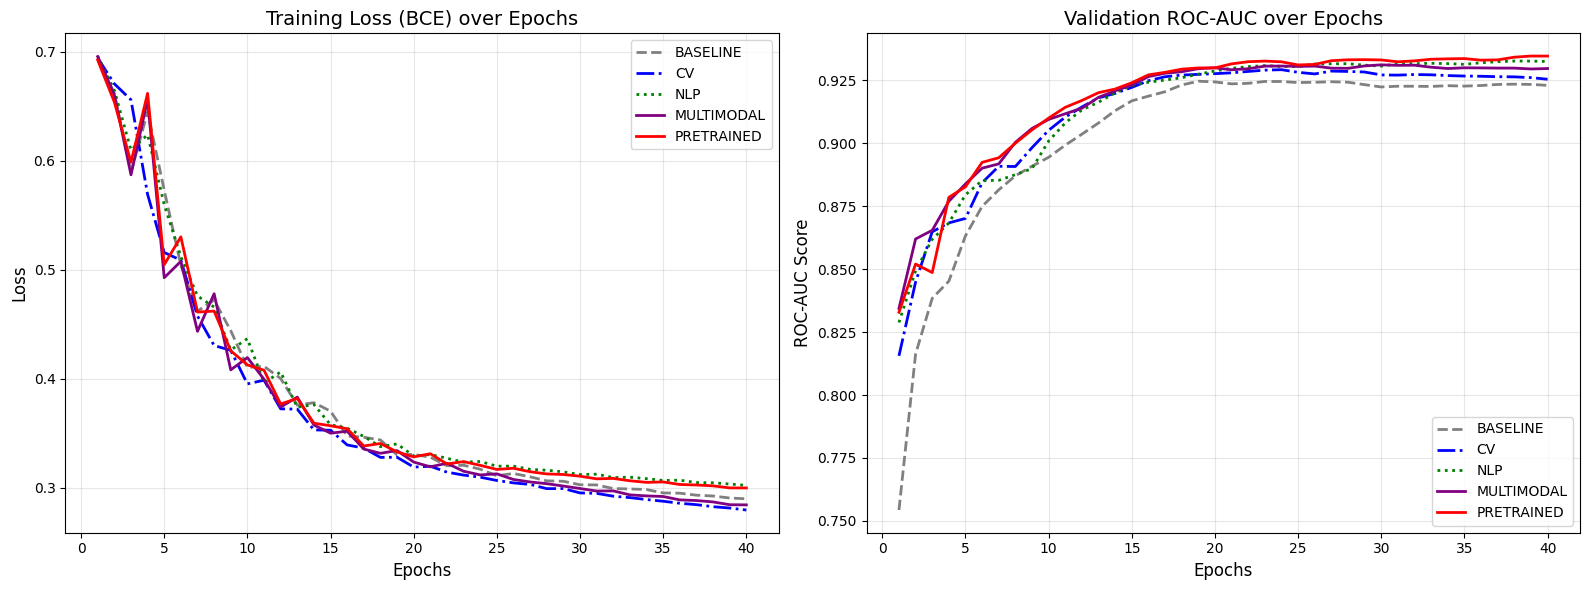

In [49]:
results = {}
for strategy in strategies:
    print(f"Training Strategy: {strategy.upper()}")

    # 1. Get features using the helper function
    features = get_movie_features(strategy, cv_features, nlp_features, num_movies)

    # 2. Build the PyG HeteroData Graph
    graph = build_graph(features)

    # 3. Train and Evaluate
    history, _ = train_and_evaluate_graph(graph, num_epochs=40)
    results[strategy] = history

# --- PLOTTING THE COMPARISON ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
styles = ['--', '-.', ':', '-', '-']
colors = ['gray', 'blue', 'green', 'purple', 'red']

for i, (name, history) in enumerate(results.items()):
    epochs = range(1, len(history['loss']) + 1)

    ax1.plot(epochs, history['loss'], linestyle=styles[i], color=colors[i], label=name.upper(), linewidth=2)
    ax2.plot(epochs, history['val_auc'], linestyle=styles[i], color=colors[i], label=name.upper(), linewidth=2)

ax1.set_title('Training Loss (BCE) over Epochs', fontsize=14)
ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.set_title('Validation ROC-AUC over Epochs', fontsize=14)
ax2.set_xlabel('Epochs', fontsize=12)
ax2.set_ylabel('ROC-AUC Score', fontsize=12)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

---
### **Questions**

1. If the movie features are random noise, how is the model still successfully predicting links? What does this tell you about the power of the Graph Structure (the edges) versus the Node Features?

2. Is there significant differences between using one modality over the other?

3. Did the pretrained embeddings result in better performance? Why or why not do you think that is?

Your answers:
1. The model succesfully predicts links due to the graph structure. Through message passing the embeddings of the nodes are updated based on their neighbors. The edges contain very useful information like movie or user similarities so the gnn learns effectively from the connectivity patterns.
2. There are no significant differences as their ROC-AUC score is around 0.92. This means that the graph structure is able to make accurate predictions without needing much additional semantic information.
3. We observe that the pretrained embeddings achieve slightly better performance because they already contain semantic information extracted from large datasets, improving the quality of the movie representations.

---
### **Qualitative analysis**

While AUC scores and loss curves are essential for measuring model performance, the true test of a recommendation system is its ability to provide tangible, human-readable results.

In this section, you will implement an **Inference Pipeline**, i.e. asking the model to predict the existence of *entirely new* edges, and printing the results.

To generate a "Top-5" list for a specific user, your code must execute the following logic:

1.  **Extract User History**: Identify the movies User $X$ has already rated in the graph. We do this to ensure we don't recommend movies they have already seen.
2.  **Candidate Generation**: Identify every movie in the `movie_mapping` that does *not* appear in the user's history.
3.  **Link Prediction**: Construct a set of "potential edges" between User $X$ and every candidate movie. Pass these into your trained GNN to calculate a **Match Probability** (0.0 to 1.0).
4.  **Ranking and Mapping**: Sort the candidates by their probability scores, select the top $K$, and map the internal Graph IDs back to human-readable titles using your metadata.


In [76]:
import torch
import pandas as pd
import numpy as np

def recommend_movies_for_user(user_id, model, graph_data, metadata_df, user_mapping, movie_mapping, top_k=5):
    """Generates human-readable movie recommendations for a specific user in the following fomat:
    --- USER X HISTORY ---
    They have already rated N movies. Here are a few:
       Movie 1
       Movie 2
       Movie 3
       Movie 4
       Movie 5


    --- TOP 5 GNN RECOMMENDATIONS ---
       Movie 1 (Probability)
       Movie 2 (Probability)
       Movie 3 (Probability)
       Movie 4 (Probability)
       Movie 5 (Probability)
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    graph_data = graph_data.to(device)
    model.eval()

    # TODO: Complete the Recommendation Engine

    # 1. Reverse the `movie_mapping` dictionary so you can convert Graph IDs back to MovieLens IDs.
    #    Also, create a dictionary from `metadata_df` to look up movie titles by their MovieLens ID.
    reverse_movie_mapping = {v:k for k,v in movie_mapping.items()}
    findtitle = metadata_df.set_index('movieId')['title'].to_dict()
    # 2. Find the internal Graph ID for the requested `user_id` using `user_mapping`.
    #    (Optional: Add a print statement and return if the user isn't in the graph).
    if user_id not in user_mapping:
        print("the user is not in the graph")
        return
    user_graph_id = user_mapping[user_id]
    # 3. Find all movies the user has ALREADY rated.
    #    Hint: Look at the full, undivided edge_index to find edges connected to this user.
    #    Print the user's history (show up to 5 movie titles they have rated).
    rated_movie_graph_ids = []

    for i in range(edge_index.shape[1]):

        src_user = edge_index[0][i].item()
    
        dst_movie = edge_index[1][i].item()
    
        if src_user == user_graph_id:
            rated_movie_graph_ids.append(dst_movie)
            
    for movie_graph_id in rated_movie_graph_ids[:5]:
        movielens_id = reverse_movie_mapping[movie_graph_id]
        title = findtitle[movielens_id]
        print(f"   {title}")
        
    # 4. Find all candidate movies (Movies this user has NOT rated yet).
    all_movie_graph_ids = set(movie_mapping.values())
    rated_movie_graph_ids_set = set(map(int, rated_movie_graph_ids))
    candidate_movie_graph_ids = list(all_movie_graph_ids - rated_movie_graph_ids_set)
    
    # 5. Create a `pred_edge_index` tensor of shape [2, num_candidates].
    #    Row 0 should be the user's Graph ID repeating.
    #    Row 1 should be the candidate movie Graph IDs.
    #    Move this tensor to the device.

    user_tensor = torch.full(
        (len(candidate_movie_graph_ids),),
        user_graph_id,
        dtype=torch.long
    )

    movie_tensor = torch.tensor(
        candidate_movie_graph_ids,
        dtype=torch.long
    )

    pred_edge_index = torch.stack([user_tensor, movie_tensor], dim=0).to(device)

    # 6. Forward Pass: Ask the GNN to predict the probability of these candidate edges.
    #    Pass the full graph structure (edge_index_dict) to the model, so it can aggregate neighbors,
    #    but ask it to decode ONLY our new pred_edge_index.
    with torch.no_grad():
        logits = model(
            graph_data.x_dict,
            graph_data.edge_index_dict,
            pred_edge_index
        )

        probs = torch.sigmoid(logits)

    # 7. Sort the predictions to find the indices of the `top_k` highest probabilities.
    #    Print the final recommendations, converting the Graph IDs back to actual Movie Titles.

    top_k = min(top_k, len(candidate_movie_graph_ids))
    top_probs, top_indices = torch.topk(probs, k=top_k)

    print(f"\n--- TOP {top_k} GNN RECOMMENDATIONS ---")

    for prob, idx in zip(top_probs.cpu(), top_indices.cpu()):
        movie_graph_id = candidate_movie_graph_ids[int(idx)]
        movielens_id = reverse_movie_mapping[int(movie_graph_id)]
        title = findtitle.get(movielens_id, "Unknown title")

        print(f"   {title} ({prob.item():.4f})")

In [81]:
graph = build_graph(get_movie_features("cv", cv_features, nlp_features, num_movies))
_, model = train_and_evaluate_graph(graph, num_epochs=40)

recommend_movies_for_user(
    user_id=22,
    model=model, # Your trained GNN
    graph_data=graph, # Pass the full graph object so it has the structural context
    metadata_df=small_full, # The dataframe with movie titles
    user_mapping=user_mapping,
    movie_mapping=movie_mapping,
    top_k=5
)

   Muppet Treasure Island (1996)
   Billy Madison (1995)
   Interview with the Vampire: The Vampire Chronicles (1994)
   Shawshank Redemption, The (1994)
   Forrest Gump (1994)

--- TOP 5 GNN RECOMMENDATIONS ---
   Firm, The (1993) (0.9843)
   Apollo 13 (1995) (0.9829)
   Cliffhanger (1993) (0.9829)
   Die Hard: With a Vengeance (1995) (0.9807)
   Leaving Las Vegas (1995) (0.9802)
